# Simulations

Here, we simulate an evolution experiment and apply MPL to estimate the selection coefficient of each mutation, and then estimate the overall population fitness, as with the HIV LTEE.    


We then change the parameters of the simulation to explore the accuracy of MPL for estimating population fitness in different scenarios.

In [52]:
import numpy as np
import pandas as pd

from scipy.linalg import solve
from scipy.stats import rv_continuous
from scipy.stats import linregress
from scipy import stats
from sklearn.metrics import root_mean_squared_error

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes

In [53]:
fig_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/figures"

## Parameters

In [54]:
population_size = 1000 #Total number of evolving sequences
mutation_probability = 0.001 #Symmetric mutation probability per locus per generation
generations = 1500 #Total number of replication generations to simulate
loci = 50 #Number of loci on the genome
num_unique_seqs = 3 #Number unique sequences in initial (random) population
gamma = 2 #Regularisation parameter lambda (can be lower for simulations than real data)
number_sequences_per_time_point = 100  #Number of sequences sampled at each time point (<= population size)
time_between_samples = 1 #Number of generations between samples (>= 1)

## Define DFE

In [55]:
#Define Gaussian distribution
class continuous_dfe(rv_continuous):

    def __init__(self, alpha, beta, *args, **kwargs):
        super().__init__(a=-np.inf, b=np.inf, *args, **kwargs)
        self.alpha = alpha
        self.beta = beta
        self.N = (2/np.sqrt(np.pi))/(1/np.sqrt(beta) + 1/np.sqrt(alpha))


    def _pdf(self, x):
        return np.where(x>0, self.N*np.exp(-self.alpha*(x**2)), self.N*np.exp(-self.beta*(x**2)))


#Sample from the DFE
alpha = 0.4
beta = 0.1
dist = continuous_dfe(alpha=alpha, beta=beta, seed=1) #can change alpha and beta parameters
samples = dist.rvs(size=loci)

#Calculate selection coefficients
selection_coefficients = np.sort(samples/100)

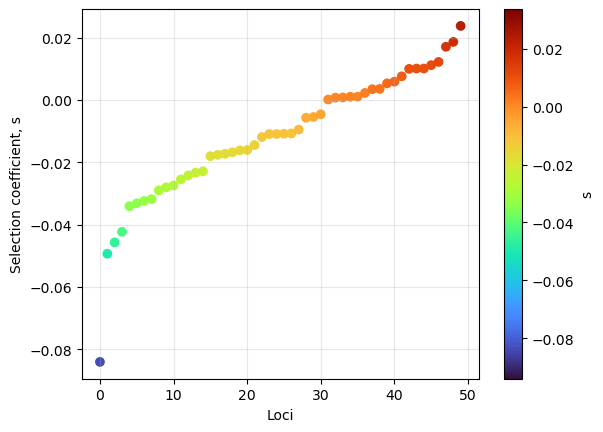

In [56]:
#Plot selection coefficients
scatter = plt.scatter(np.arange(loci), selection_coefficients, c=selection_coefficients, vmin=selection_coefficients.min()-0.01, vmax=selection_coefficients.max()+0.01, cmap='turbo')
plt.colorbar(scatter, label='s')
plt.xlabel('Loci')
plt.ylabel('Selection coefficient, s')
# plt.title('Selection coefficients of all mutant alleles on the genome')
plt.grid(alpha=0.3)
plt.savefig(fig_path + f"/simulations_selection_coefficients.pdf")
plt.show()

## Simulate Wright-Fisher trajectories

In [57]:
def simulate_wf(population_size, mutation_probability, generations, loci, num_unique_seqs, selection_coefficients, time_between_samples, number_sequences_per_time_point):

    #### Initialise lists to store evolution trajectory ####

    population_seqs = [[] for _ in range(generations+1)]
    population_seq_nums = [[] for _ in range(generations+1)]


    #### Define the initial population as all WT ####
    population_seqs[0].append(np.array([0]*loci))
    population_seq_nums[0] = np.array([population_size])


    #### Simulate evolution of initial population including selection and mutation ####

    for g in range(1,generations+1):
        #Simulate selection
        fitnesses = 1 + (population_seqs[g-1]*selection_coefficients).sum(axis=1) #additive fitness
        p = (fitnesses*population_seq_nums[g-1])/(fitnesses*population_seq_nums[g-1]).sum()
        new_nums = np.random.multinomial(population_size, pvals = p)

        #Simulate mutations
        new_seqs = [seq.copy() for seq in population_seqs[g-1]]

        for i in range(len(population_seqs[g-1])):
            num_mutants = np.random.binomial(new_nums[i], mutation_probability*loci) #approx number of mutant sequences for small mut prob
            new_nums[i] -= num_mutants #remove mutants from original sequence count
            for j in range(num_mutants):
                mutant_loci = np.random.randint(loci) #choose one locus at random to be mutated 
                new_seq = population_seqs[g-1][i].copy()
                new_seq[mutant_loci] = 1 - new_seq[mutant_loci] #mutate locus of original sequence

                #Update sequences and frequencies
                matches = [np.array_equal(new_seq, x) for x in new_seqs] 
                if any(matches):
                    idx = matches.index(True)
                    new_nums[idx] += 1
                else:
                    new_seqs.append(new_seq)
                    new_nums = np.concatenate((new_nums,[1]))

        #Remove sequences with zero frequency
        idx_to_remove = np.where(new_nums == 0)[0]
        new_seqs = [s for k,s in enumerate(new_seqs) if k not in idx_to_remove]
        new_nums = np.array([n for k,n in enumerate(new_nums) if k not in idx_to_remove])

        #Store sequences, and frequencies
        population_seqs[g] = new_seqs
        population_seq_nums[g] = new_nums



    #### Sample simulated trajectories ####

    #Sample specific generations
    sampled_seqs = population_seqs[::time_between_samples]
    sampled_seq_nums = population_seq_nums[::time_between_samples]

    #Choose sequences at random from each sample time
    for i in range(len(sampled_seqs)):
        idx = np.repeat(np.arange(len(sampled_seqs[i])),sampled_seq_nums[i])
        sample = np.random.choice(idx, size=number_sequences_per_time_point, replace=False)
        sample_idx, sample_counts = np.unique(sample, return_counts=True)
        sampled_seqs[i] = [sampled_seqs[i][j] for j in sample_idx]
        sampled_seq_nums[i] = sample_counts



    return sampled_seqs, sampled_seq_nums

## No linkage estimate

In [58]:
def no_linkage_inference(seqs, nums, loci, number_sequences_per_time_point, time_between_samples, mutation_probability):
    #Calculate allele frequencies
    x = np.zeros((loci,len(seqs)))
    for i in range(len(seqs)):
        x[:,i] = np.sum([seq*num for seq,num in zip(seqs[i],nums[i])],axis=0)/number_sequences_per_time_point


    #Calculate integrated drift term
    C_diag = np.zeros(loci)
    for k in range(len(seqs)-1):
        C_diag += time_between_samples*((x[:,k+1] + x[:,k])/2 - (np.square(x[:,k+1]) + np.square(x[:,k]) + np.multiply(x[:,k+1],x[:,k]))/3)


    #Calculate integrated mutational flux vector
    mu_fl = np.zeros(loci)
    for k in range(len(seqs)-1):
        mu_fl += mutation_probability*time_between_samples*(1-(x[:,k+1] + x[:,k]))


    #Solve for selection coefficients
    s = np.divide((x[:,-1] - x[:,0] - mu_fl),C_diag)

    return s

## MPL estimate

In [59]:
def MPL_inference(seqs, nums, loci, number_sequences_per_time_point, time_between_samples, mutation_probability, gamma):

    #### Calculate single allele frequencies, x ####
    x = np.zeros((loci,len(seqs)))
    for i in range(len(seqs)):
        x[:,i] = np.sum([seq*num for seq,num in zip(seqs[i],nums[i])],axis=0)/number_sequences_per_time_point


    #### Calculate double allele frequencies, x_d ####
    x_d = np.zeros((loci,loci,len(seqs)))

    for g in range(len(seqs)):
        for seq,num in zip(seqs[g], nums[g]):
            seq_tiled = np.tile(seq, (loci,1))
            x_d[:,:,g] += np.multiply(seq_tiled, seq_tiled.T)*num/number_sequences_per_time_point


    #### Calculate integrated covariance matrix ####
    C_int = np.zeros((loci,loci))

    #Non-diagonal elements
    for k in range(len(seqs)-1):
        C_int += time_between_samples*((x_d[:,:,k+1] + x_d[:,:,k])/2 -
                                    (np.outer(x[:,k],x[:,k])+np.outer(x[:,k+1],x[:,k+1]))/3 - 
                                    (np.outer(x[:,k],x[:,k+1])+np.outer(x[:,k+1],x[:,k]))/6)
        
    #Diagonal elements
    diag = np.zeros(loci)
    for k in range(len(seqs)-1):
        diag += time_between_samples*((x[:,k+1] + x[:,k])/2 -
                                    (np.square(x[:,k+1]) + np.square(x[:,k]) + np.multiply(x[:,k+1],x[:,k]))/3)
    np.fill_diagonal(C_int,diag)


    #### Calculate integrated flux vector ####
    mu_fl = np.zeros(loci)
    for k in range(len(seqs)-1):
        mu_fl += mutation_probability*time_between_samples*(1-(x[:,k+1] + x[:,k]))

    #### Solve for selection coefficients ####
    s = solve(C_int + gamma*np.identity(loci), x[:,-1] - x[:,0] - mu_fl, assume_a='gen')


    return s, C_int

## Run one population fitness simulation

Population fitness is defined as the weighted sum of selection coefficients (the weights are the frequency of each mutation)

In [99]:
#Takes ~1 minute
number_simulations = 3
population_size = 1000 #Total number of evolving sequences
mutation_probability = 0.001 #Symmetric mutation probability per locus per generation
generations = 1500 #Total number of replication generations to simulate

s_MPL_all_1000 = []
s_no_linkage_all_1000 = []
rmse_1000 = np.zeros((2,number_simulations))
pop_s_1000 = np.zeros((number_simulations,generations))
pop_s_no_linkage_1000 = np.zeros((number_simulations,generations))
pop_s_MPL_1000 = np.zeros((number_simulations,generations))

for j in range(number_simulations):

    #Run simulation
    sequences, numbers = simulate_wf(population_size, mutation_probability, generations, loci, num_unique_seqs, selection_coefficients, time_between_samples, population_size)
    s_MPL, C_int = MPL_inference(sequences, numbers, loci, population_size, time_between_samples, mutation_probability, gamma)
    s_no_linkage = no_linkage_inference(sequences, numbers, loci, population_size, time_between_samples, mutation_probability)

    #Store s estimates
    s_MPL_all_1000.append(s_MPL)
    s_no_linkage_all_1000.append(s_no_linkage)

    #Calculate true population fitness
    for g in range(1,generations):
        pop_s_1000[j,g] = ((sequences[g-1]*selection_coefficients).sum(axis=1) * numbers[g-1]).sum()/population_size
        
    #Calculate inferred population fitness
    x = np.zeros((loci,generations))
    for i in range(generations):
        x[:,i] = np.sum([seq*num for seq,num in zip(sequences[i],numbers[i])],axis=0)/population_size
    pop_s_no_linkage_1000[j,:] = (x * s_no_linkage[:, np.newaxis]).sum(axis=0)
    pop_s_MPL_1000[j,:] = (x * s_MPL[:, np.newaxis]).sum(axis=0)

    #Save RMSE
    rmse_1000[0,j] = root_mean_squared_error(pop_s_1000[j,:],pop_s_no_linkage_1000[j,:])
    rmse_1000[1,j] = root_mean_squared_error(pop_s_1000[j,:],pop_s_MPL_1000[j,:])



/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_53990/2862886830.py:66: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


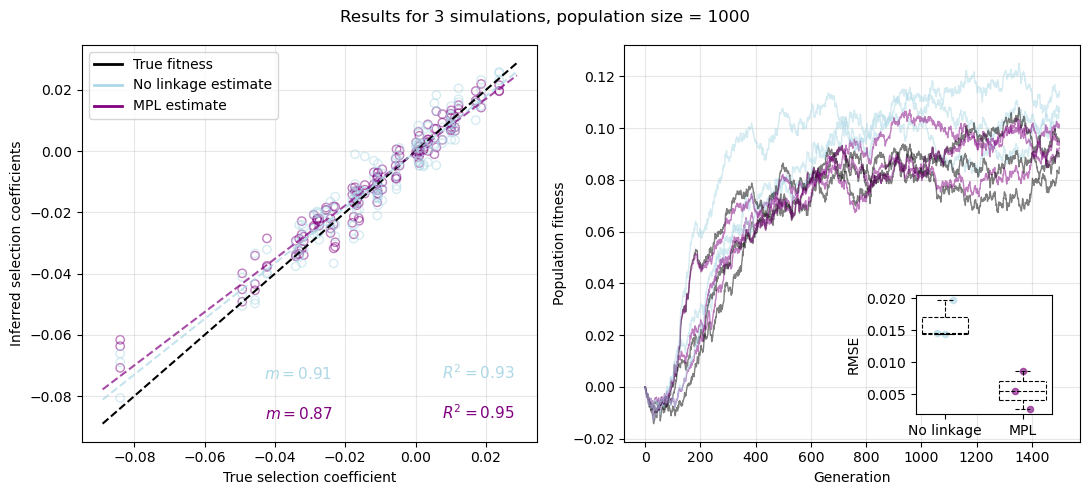

In [100]:
#Plot results
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(11,5))
ax2_ins = inset_axes(ax2, width="30%", height="30%", loc='lower right', borderpad=2)

for j in range(number_simulations):

    #Plot population fitness
    ax2.plot(np.arange(generations),pop_s_1000[j,:],label='True population fitness',color='black',alpha=0.5,linewidth=1)
    ax2.plot(np.arange(generations),pop_s_MPL_1000[j,:],label='MPL estimate',color='purple',alpha=0.5,linewidth=1)
    ax2.plot(np.arange(generations),pop_s_no_linkage_1000[j,:],label='No linkage estimate',color='lightblue',alpha=0.5,linewidth=1)


#Plot selection coefficient scatters
selection_coefficients_all_1000 = np.tile(selection_coefficients,number_simulations)
ax1.scatter(selection_coefficients_all_1000, np.concat(s_MPL_all_1000), label='MPL estimate',facecolors='none', edgecolors='purple',alpha=0.5)
ax1.scatter(selection_coefficients_all_1000, np.concat(s_no_linkage_all_1000), label='No linkage estimate', facecolors='none', edgecolors='lightblue',alpha=0.5)
l = np.linspace(selection_coefficients.min()-0.005,selection_coefficients.max()+0.005,10)
ax1.plot(l,l,'--',color='black')

#Plot linear regressions
m, c, r, p, std_err = stats.linregress(selection_coefficients_all_1000, np.concat(s_MPL_all_1000))
ax1.plot(l,m*l+c,'--',color='purple',alpha=0.7)
ax1.text(0.95,0.05,f'$R^2=${r**2:.2f}',color='purple',fontsize=11,transform=ax1.transAxes, ha='right', va='bottom')
ax1.text(0.55,0.05,f'$m=${m:.2f}',color='purple',fontsize=11,transform=ax1.transAxes, ha='right', va='bottom')

m, c, r, p, std_err = stats.linregress(selection_coefficients_all_1000, np.concat(s_no_linkage_all_1000))
ax1.plot(l,m*l+c,'--',color='lightblue',alpha=0.7)
ax1.text(0.95,0.15,f'$R^2=${r**2:.2f}',color='lightblue',fontsize=11,transform=ax1.transAxes, ha='right', va='bottom')
ax1.text(0.55,0.15,f'$m=${m:.2f}',color='lightblue',fontsize=11,transform=ax1.transAxes, ha='right', va='bottom')

#Plot RMSE
colours = ['lightblue','purple']
for i in range(2):
    ax2_ins.scatter(i+np.linspace(-0.1,0.1,number_simulations),rmse_1000[i,:],s=20,marker='o',color=colours[i],alpha=0.6)
    ax2_ins.plot(i+np.linspace(-0.3,0.3,5),np.median(rmse_1000[i,:])+np.zeros(5),'--',color='black',linewidth=0.8)
    q1 = np.percentile(rmse_1000[i,:],25)
    q2 = np.percentile(rmse_1000[i,:],75)
    ax2_ins.plot(i+np.linspace(-0.3,0.3,5),q1+np.zeros(5),'--',color='black',linewidth=0.8)
    ax2_ins.plot(i+np.linspace(-0.3,0.3,5),q2+np.zeros(5),'--',color='black',linewidth=0.8)
    ax2_ins.plot(i+np.zeros(5)-0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
    ax2_ins.plot(i+np.zeros(5)+0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
    ax2_ins.plot(i+np.zeros(5),np.linspace(q2,rmse_1000[i,:].max(),5),'--',color='black',linewidth=0.8)
    ax2_ins.plot(i+np.zeros(5),np.linspace(rmse_1000[i,:].min(),q1,5),'--',color='black',linewidth=0.8)
    ax2_ins.plot(i+np.linspace(-0.1,0.1,5),rmse_1000[i,:].max()+np.zeros(5),'--',color='black',linewidth=0.8)
    ax2_ins.plot(i+np.linspace(-0.1,0.1,5),rmse_1000[i,:].min()+np.zeros(5),'--',color='black',linewidth=0.8)


#Format
ax1.grid(alpha=0.3)
ax2.grid(alpha=0.3)
ax1.set_xlabel('True selection coefficient')
ax1.set_ylabel('Inferred selection coefficients')
ax2.set_xlabel('Generation')
ax2.set_ylabel('Population fitness')
ax2_ins.set_xticks(ticks=[0,1],labels=['No linkage','MPL'])
ax2_ins.set_ylabel('RMSE')

#Legend
custom_lines = [Line2D([0], [0], color='black', lw=2),
                Line2D([0], [0], color='lightblue', lw=2),
                Line2D([0], [0], color='purple', lw=2)]

ax1.legend(custom_lines, ['True fitness', 'No linkage estimate', 'MPL estimate'],fontsize=10,loc='upper left')

plt.suptitle(f'Results for {number_simulations} simulations, population size = {population_size}')
plt.tight_layout()
plt.savefig(fig_path + f"/simulations_three_reps.pdf")
plt.show()

Underestimation of magnitude of mutations:

The magnitude of mutations are systematically underestimated, which was also seen before in other simulations. This causes an underestimation of the total population fitness, as this is made up of (more and more) beneficial mutations. This seems to be due to clonal interference, since the effect decreases with fewer loci. This makes sense as with more mutations in the population, more are likely to beneficial and so compete for frequency. Hence, they reach lower frequencies, or reach the highest frequencies slower and so are underestimated by MPL. 


## Change population size

In [102]:
#Takes ~5 minutes
number_simulations = 10
population_size_ = [100,500,1000]
mutation_probability = 0.001 #Symmetric mutation probability per locus per generation
generations = 1500 #Total number of replication generations to simulate

rmse = np.zeros((3,2,number_simulations))
pop_s = np.zeros((3,number_simulations,generations))
pop_s_no_linkage = np.zeros((3,number_simulations,generations))
pop_s_MPL = np.zeros((3,number_simulations,generations))
s_MPL_all = np.zeros((3,number_simulations,loci))
s_no_linkage_all = np.zeros((3,number_simulations,loci))

for j in range(3):

    population_size = population_size_[j]

    for k in range(number_simulations):
        #Run simulation
        sequences, numbers = simulate_wf(population_size, mutation_probability, generations, loci, num_unique_seqs, selection_coefficients, time_between_samples, population_size)
        s_MPL, C_int = MPL_inference(sequences, numbers, loci, population_size, time_between_samples, mutation_probability, gamma)
        s_no_linkage = no_linkage_inference(sequences, numbers, loci, population_size, time_between_samples, mutation_probability)

        #Store s estimates
        s_MPL_all[j,k,:] = s_MPL
        s_no_linkage_all[j,k,:] = s_no_linkage
        
        #Calculate true population fitness
        for g in range(1,generations):
            pop_s[j,k,g] = ((sequences[g-1]*selection_coefficients).sum(axis=1) * numbers[g-1]).sum()/population_size
        
        #Calculate inferred population fitness
        x = np.zeros((loci,generations))
        for g in range(generations):
            x[:,g] = np.sum([seq*num for seq,num in zip(sequences[g],numbers[g])],axis=0)/population_size
        pop_s_no_linkage[j,k,:] = (x * s_no_linkage[:, np.newaxis]).sum(axis=0)
        pop_s_MPL[j,k,:] = (x * s_MPL[:, np.newaxis]).sum(axis=0)

        #Save RMSE
        rmse[j,0,k] = root_mean_squared_error(pop_s[j,k,:],pop_s_no_linkage[j,k,:])
        rmse[j,1,k] = root_mean_squared_error(pop_s[j,k,:],pop_s_MPL[j,k,:])

        

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_53990/3914114106.py:81: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


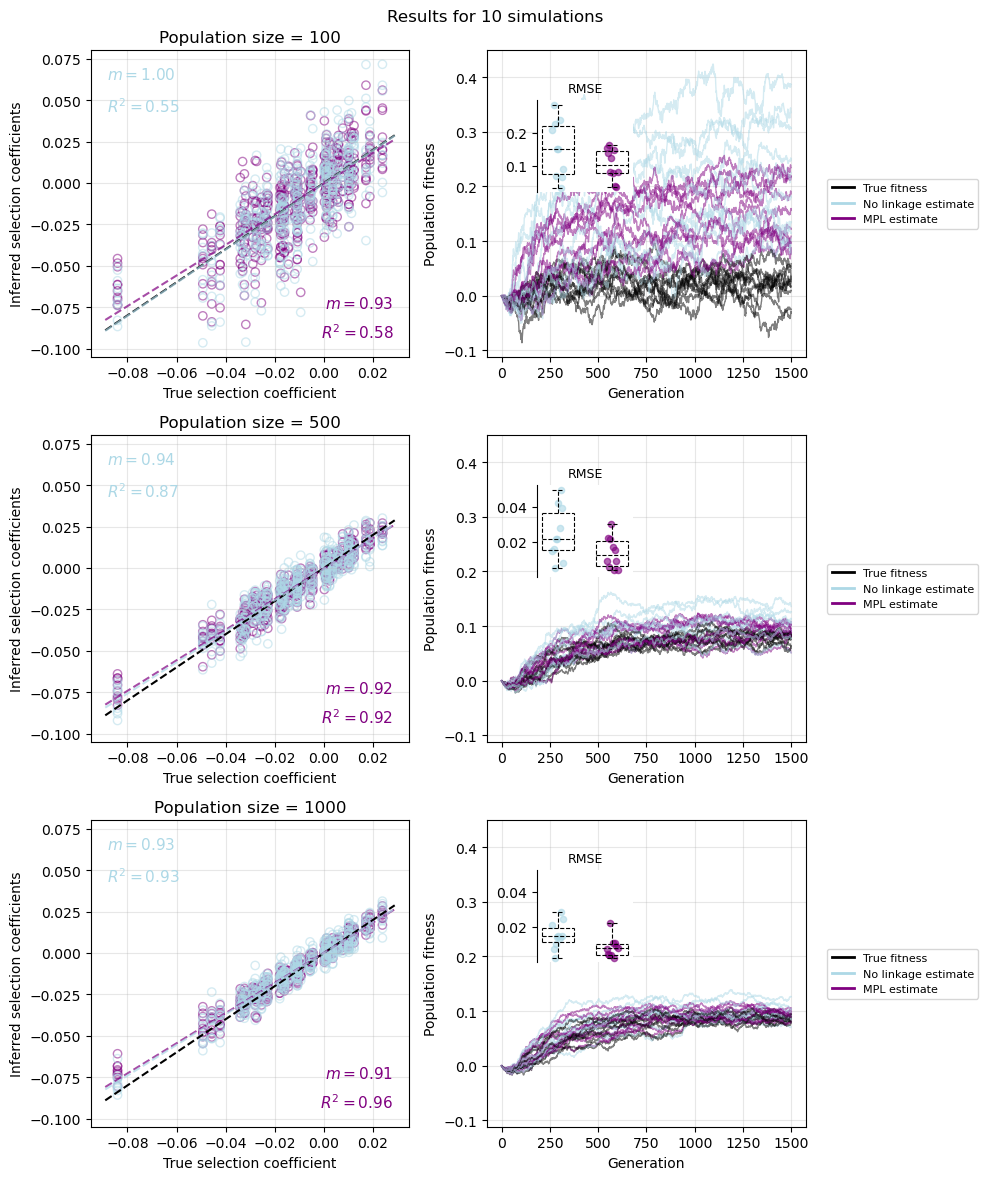

In [103]:
#Plot results
fig, axes = plt.subplots(3,2,figsize=(10,12))
axes[1, 0].sharey(axes[0, 0])
axes[2, 0].sharey(axes[0, 0])
axes[1, 1].sharey(axes[0, 1])
axes[2, 1].sharey(axes[0, 1])

ax_ins_0 = inset_axes(axes[0,1], width="30%", height="30%", loc='upper left', borderpad=3.6)
ax_ins_1 = inset_axes(axes[1,1], width="30%", height="30%", loc='upper left', borderpad=3.6)
ax_ins_2 = inset_axes(axes[2,1], width="30%", height="30%", loc='upper left', borderpad=3.6)
ax_ins_2.sharey(ax_ins_1)
ax_ins = [ax_ins_0,ax_ins_1,ax_ins_2]

selection_coefficients_all = np.tile(selection_coefficients,number_simulations)

for j in range(3):
    for k in range(number_simulations):

        #Plot population fitness
        axes[j,1].plot(np.arange(generations),pop_s[j,k,:],label='True population fitness',color='black',alpha=0.5,linewidth=1)
        axes[j,1].plot(np.arange(generations),pop_s_MPL[j,k,:],label='MPL estimate',color='purple',alpha=0.5,linewidth=1)
        axes[j,1].plot(np.arange(generations),pop_s_no_linkage[j,k,:],label='No linkage estimate',color='lightblue',alpha=0.5,linewidth=1)

    #Plot selection coefficient scatters
    axes[j,0].scatter(selection_coefficients_all, s_MPL_all[j,:,:].flatten(), label='MPL estimate',facecolors='none', edgecolors='purple',alpha=0.5)
    axes[j,0].scatter(selection_coefficients_all, s_no_linkage_all[j,:,:].flatten(), label='No linkage estimate', facecolors='none', edgecolors='lightblue',alpha=0.5)
    l = np.linspace(selection_coefficients.min()-0.005,selection_coefficients.max()+0.005,10)
    axes[j,0].plot(l,l,'--',color='black')

    #Plot linear regressions
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, s_MPL_all[j,:,:].flatten())
    axes[j,0].plot(l,m*l+c,'--',color='purple',alpha=0.7)
    axes[j,0].text(0.95,0.05,f'$R^2=${r**2:.2f}',color='purple',fontsize=11,transform=axes[j,0].transAxes, ha='right', va='bottom')
    axes[j,0].text(0.95,0.15,f'$m=${m:.2f}',color='purple',fontsize=11,transform=axes[j,0].transAxes, ha='right', va='bottom')
    
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, s_no_linkage_all[j,:,:].flatten())
    axes[j,0].plot(l,m*l+c,'--',color='lightblue',alpha=0.7)
    axes[j,0].text(0.05,0.85,f'$R^2=${r**2:.2f}',color='lightblue',fontsize=11,transform=axes[j,0].transAxes, ha='left', va='top')
    axes[j,0].text(0.05,0.95,f'$m=${m:.2f}',color='lightblue',fontsize=11,transform=axes[j,0].transAxes, ha='left', va='top')

    #Plot RMSE
    colours = ['lightblue','purple']

    for i in range(2):
        ax_ins[j].scatter(i+np.linspace(-0.1,0.1,number_simulations),rmse[j,i,:],s=20,marker='o',color=colours[i],alpha=0.6)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),np.median(rmse[j,i,:])+np.zeros(5),'--',color='black',linewidth=0.8)
        q1 = np.percentile(rmse[j,i,:],25)
        q2 = np.percentile(rmse[j,i,:],75)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q1+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q2+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)-0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)+0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(q2,rmse[j,i,:].max(),5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(rmse[j,i,:].min(),q1,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse[j,i,:].max()+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse[j,i,:].min()+np.zeros(5),'--',color='black',linewidth=0.8)


    #Format
    for i in range(2):
        axes[j,i].grid(alpha=0.3)
    axes[j,0].set_xlabel('True selection coefficient')
    axes[j,0].set_ylabel('Inferred selection coefficients')
    axes[j,1].set_xlabel('Generation')
    axes[j,1].set_ylabel('Population fitness')
    axes[j,0].set_title(f'Population size = {population_size_[j]}')
    ax_ins[j].set_title('RMSE',fontsize=9)
    ax_ins[j].spines['top'].set_visible(False)
    ax_ins[j].spines['right'].set_visible(False)
    ax_ins[j].spines['bottom'].set_visible(False)
    ax_ins[j].set_xticks([])

    #Legend
    custom_lines = [Line2D([0], [0], color='black', lw=2),
                    Line2D([0], [0], color='lightblue', lw=2),
                    Line2D([0], [0], color='purple', lw=2)]

    axes[j,1].legend(custom_lines, ['True fitness', 'No linkage estimate', 'MPL estimate'],fontsize=8,loc='center left', bbox_to_anchor=(1.05, 0.5), frameon=True)

plt.suptitle(f'Results for {number_simulations} simulations')
plt.tight_layout()
plt.savefig(fig_path + f"/simulations_changing_population_size.pdf")
plt.show()

Estimates are much better, and have a much lower variance, with large population sizes. This is because drift is proportional to 1/N so for small populations drift plays a larger role than selection. This obscures our estimates. Mathematically, we find that for selection >> drift, we require s>>1/N (this is also an assumption of MPL). Here, since s~0.01, we require N>>100. Cheng et al. 2025 quanitfy variance due to drift, and also due to limited sampling.

## Figure 4

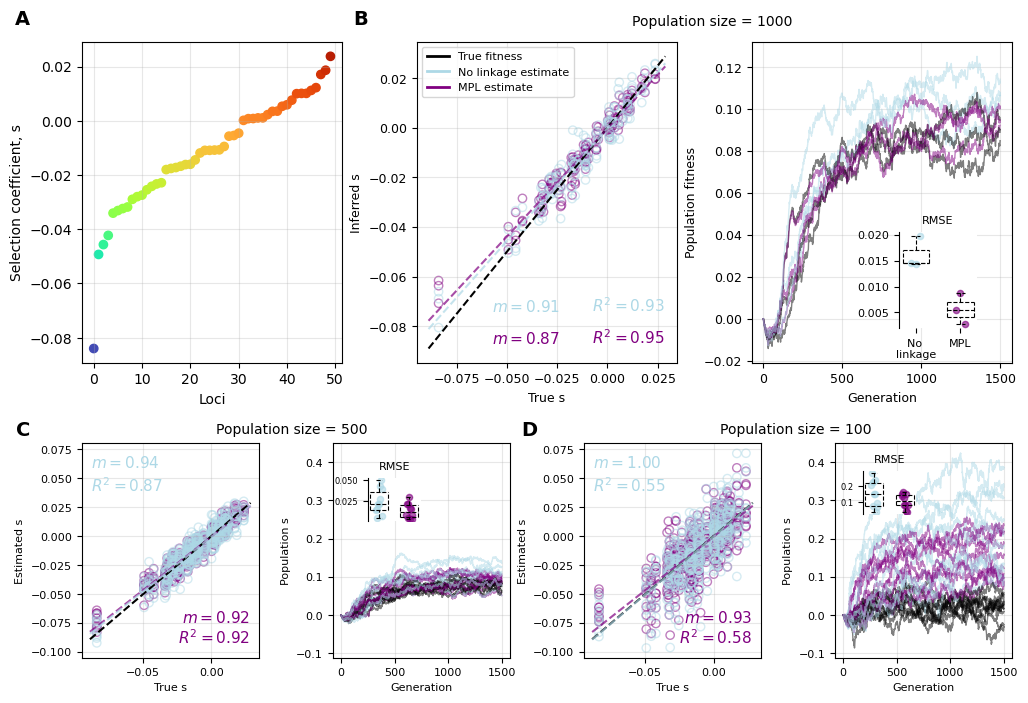

In [104]:
fig = plt.figure(figsize=(12, 8))

#Define grid
gs = fig.add_gridspec(nrows=2,ncols=12,height_ratios=[1.5,1],wspace=8,hspace=0.3)
ax1 = fig.add_subplot(gs[0, 0:4])
ax2 = fig.add_subplot(gs[0, 4:8])
ax3 = fig.add_subplot(gs[0, 8:12])
ax4 = fig.add_subplot(gs[1, 0:3])
ax5 = fig.add_subplot(gs[1, 3:6])
ax6 = fig.add_subplot(gs[1, 6:9])
ax7 = fig.add_subplot(gs[1, 9:12])

#True selection coefficients
scatter = ax1.scatter(np.arange(loci), selection_coefficients, c=selection_coefficients, vmin=selection_coefficients.min()-0.01, vmax=selection_coefficients.max()+0.01, cmap='turbo')
ax1.set_xlabel('Loci')
ax1.set_ylabel('Selection coefficient, s')
ax1.grid(alpha=0.3)
ax1.text(-0.2, 1.1, 'A', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')


#Population size 1000
ax3_ins = inset_axes(ax3, width="30%", height="30%", loc='lower right', borderpad=2.5)
number_simulations = 3
for j in range(number_simulations):

    #Plot population fitness
    ax3.plot(np.arange(generations),pop_s_1000[j,:],label='True population fitness',color='black',alpha=0.5,linewidth=1)
    ax3.plot(np.arange(generations),pop_s_MPL_1000[j,:],label='MPL estimate',color='purple',alpha=0.5,linewidth=1)
    ax3.plot(np.arange(generations),pop_s_no_linkage_1000[j,:],label='No linkage estimate',color='lightblue',alpha=0.5,linewidth=1)


#Plot selection coefficient scatters
selection_coefficients_all_1000 = np.tile(selection_coefficients,number_simulations)
ax2.scatter(selection_coefficients_all_1000, np.concat(s_MPL_all_1000), label='MPL estimate',facecolors='none', edgecolors='purple',alpha=0.5)
ax2.scatter(selection_coefficients_all_1000, np.concat(s_no_linkage_all_1000), label='No linkage estimate', facecolors='none', edgecolors='lightblue',alpha=0.5)
l = np.linspace(selection_coefficients.min()-0.005,selection_coefficients.max()+0.005,10)
ax2.plot(l,l,'--',color='black')

#Plot linear regressions
m, c, r, p, std_err = stats.linregress(selection_coefficients_all_1000, np.concat(s_MPL_all_1000))
ax2.plot(l,m*l+c,'--',color='purple',alpha=0.7)
ax2.text(0.95,0.05,f'$R^2=${r**2:.2f}',color='purple',fontsize=11,transform=ax2.transAxes, ha='right', va='bottom')
ax2.text(0.55,0.05,f'$m=${m:.2f}',color='purple',fontsize=11,transform=ax2.transAxes, ha='right', va='bottom')

m, c, r, p, std_err = stats.linregress(selection_coefficients_all_1000, np.concat(s_no_linkage_all_1000))
ax2.plot(l,m*l+c,'--',color='lightblue',alpha=0.7)
ax2.text(0.95,0.15,f'$R^2=${r**2:.2f}',color='lightblue',fontsize=11,transform=ax2.transAxes, ha='right', va='bottom')
ax2.text(0.55,0.15,f'$m=${m:.2f}',color='lightblue',fontsize=11,transform=ax2.transAxes, ha='right', va='bottom')

#Plot RMSE
colours = ['lightblue','purple']
for i in range(2):
    ax3_ins.scatter(i+np.linspace(-0.1,0.1,number_simulations),rmse_1000[i,:],s=20,marker='o',color=colours[i],alpha=0.6)
    ax3_ins.plot(i+np.linspace(-0.3,0.3,5),np.median(rmse_1000[i,:])+np.zeros(5),'--',color='black',linewidth=0.8)
    q1 = np.percentile(rmse_1000[i,:],25)
    q2 = np.percentile(rmse_1000[i,:],75)
    ax3_ins.plot(i+np.linspace(-0.3,0.3,5),q1+np.zeros(5),'--',color='black',linewidth=0.8)
    ax3_ins.plot(i+np.linspace(-0.3,0.3,5),q2+np.zeros(5),'--',color='black',linewidth=0.8)
    ax3_ins.plot(i+np.zeros(5)-0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
    ax3_ins.plot(i+np.zeros(5)+0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
    ax3_ins.plot(i+np.zeros(5),np.linspace(q2,rmse_1000[i,:].max(),5),'--',color='black',linewidth=0.8)
    ax3_ins.plot(i+np.zeros(5),np.linspace(rmse_1000[i,:].min(),q1,5),'--',color='black',linewidth=0.8)
    ax3_ins.plot(i+np.linspace(-0.1,0.1,5),rmse_1000[i,:].max()+np.zeros(5),'--',color='black',linewidth=0.8)
    ax3_ins.plot(i+np.linspace(-0.1,0.1,5),rmse_1000[i,:].min()+np.zeros(5),'--',color='black',linewidth=0.8)


#Format
ax2.grid(alpha=0.3)
ax3.grid(alpha=0.3)
ax2.set_xlabel('True s',fontsize=9)
ax2.set_ylabel('Inferred s',fontsize=9)
ax3.set_xlabel('Generation',fontsize=9)
ax3.set_ylabel('Population fitness',fontsize=9)
ax3_ins.set_xticks(ticks=[0,1],labels=['No \nlinkage','MPL'])
ax3_ins.set_title('RMSE',fontsize=8)
ax3_ins.spines['top'].set_visible(False)
ax3_ins.spines['right'].set_visible(False)
ax3_ins.spines['bottom'].set_visible(False)
ax3_ins.tick_params(axis='both', labelsize=8)
ax2.tick_params(axis='both', labelsize=9)
ax3.tick_params(axis='both', labelsize=9)
ax2.text(1.1, 1.1, 'B', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')



#Legend
custom_lines = [Line2D([0], [0], color='black', lw=2),
                Line2D([0], [0], color='lightblue', lw=2),
                Line2D([0], [0], color='purple', lw=2)]

ax2.legend(custom_lines, ['True fitness', 'No linkage estimate', 'MPL estimate'],fontsize=8,loc='upper left')

fig.text(0.65,0.9,f'Population size = 1000',ha='center')


#Population size 100,500
number_simulations = 10
axes = [ax4,ax5,ax6,ax7]
ax7.sharey(ax5)
ax6.sharey(ax4)
ax_ins_0 = inset_axes(ax5, width="30%", height="20%", loc='upper left', borderpad=2.5)
ax_ins_1 = inset_axes(ax7, width="30%", height="20%", loc='upper left', borderpad=2)
ax_ins = [ax_ins_0,ax_ins_1,ax_ins_2]

selection_coefficients_all = np.tile(selection_coefficients,number_simulations)

for j in range(2):
    for k in range(number_simulations):

        #Plot population fitness
        axes[2*j+1].plot(np.arange(generations),pop_s[1-j,k,:],label='True population fitness',color='black',alpha=0.5,linewidth=1)
        axes[2*j+1].plot(np.arange(generations),pop_s_MPL[1-j,k,:],label='MPL estimate',color='purple',alpha=0.5,linewidth=1)
        axes[2*j+1].plot(np.arange(generations),pop_s_no_linkage[1-j,k,:],label='No linkage estimate',color='lightblue',alpha=0.5,linewidth=1)

    #Plot selection coefficient scatters
    axes[2*j].scatter(selection_coefficients_all, s_MPL_all[1-j,:,:].flatten(), label='MPL estimate',facecolors='none', edgecolors='purple',alpha=0.5)
    axes[2*j].scatter(selection_coefficients_all, s_no_linkage_all[1-j,:,:].flatten(), label='No linkage estimate', facecolors='none', edgecolors='lightblue',alpha=0.5)
    l = np.linspace(selection_coefficients.min()-0.005,selection_coefficients.max()+0.005,10)
    axes[2*j].plot(l,l,'--',color='black')

    #Plot linear regressions
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, s_MPL_all[1-j,:,:].flatten())
    axes[2*j].plot(l,m*l+c,'--',color='purple',alpha=0.7)
    axes[2*j].text(0.95,0.05,f'$R^2=${r**2:.2f}',color='purple',fontsize=11,transform=axes[2*j].transAxes, ha='right', va='bottom')
    axes[2*j].text(0.95,0.15,f'$m=${m:.2f}',color='purple',fontsize=11,transform=axes[2*j].transAxes, ha='right', va='bottom')
    
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, s_no_linkage_all[1-j,:,:].flatten())
    axes[2*j].plot(l,m*l+c,'--',color='lightblue',alpha=0.7)
    axes[2*j].text(0.05,0.85,f'$R^2=${r**2:.2f}',color='lightblue',fontsize=11,transform=axes[2*j].transAxes, ha='left', va='top')
    axes[2*j].text(0.05,0.95,f'$m=${m:.2f}',color='lightblue',fontsize=11,transform=axes[2*j].transAxes, ha='left', va='top')

    #Plot RMSE
    colours = ['lightblue','purple']

    for i in range(2):
        ax_ins[j].scatter(i+np.linspace(-0.1,0.1,number_simulations),rmse[1-j,i,:],s=20,marker='o',color=colours[i],alpha=0.6)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),np.median(rmse[1-j,i,:])+np.zeros(5),'--',color='black',linewidth=0.8)
        q1 = np.percentile(rmse[1-j,i,:],25)
        q2 = np.percentile(rmse[1-j,i,:],75)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q1+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q2+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)-0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)+0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(q2,rmse[1-j,i,:].max(),5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(rmse[1-j,i,:].min(),q1,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse[1-j,i,:].max()+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse[1-j,i,:].min()+np.zeros(5),'--',color='black',linewidth=0.8)


    #Format
    for i in range(2):
        axes[2*j+i].grid(alpha=0.3)
    axes[2*j].set_xlabel('True s',fontsize=8)
    axes[2*j].set_ylabel('Estimated s',fontsize=8)
    axes[2*j+1].set_xlabel('Generation',fontsize=8)
    axes[2*j+1].set_ylabel('Population s',fontsize=8)
    axes[2*j].tick_params(axis='both', labelsize=8)
    axes[2*j+1].tick_params(axis='both', labelsize=8)
    ax_ins[j].set_title('RMSE',fontsize=8)
    ax_ins[j].spines['top'].set_visible(False)
    ax_ins[j].spines['right'].set_visible(False)
    ax_ins[j].spines['bottom'].set_visible(False)
    ax_ins[j].set_xticks([])
    ax_ins[j].tick_params(axis='both', labelsize=6)

fig.text(0.3,0.39,f'Population size = 500',ha='center')
fig.text(0.72,0.39,f'Population size = 100',ha='center')
ax4.text(-0.2, -0.18, 'C', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')
ax6.text(1.75, -0.18, 'D', transform=ax1.transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

plt.savefig(fig_path + f"/Figure_4.pdf")
plt.show()

## Change mutation probability

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_93258/3085773707.py:130: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


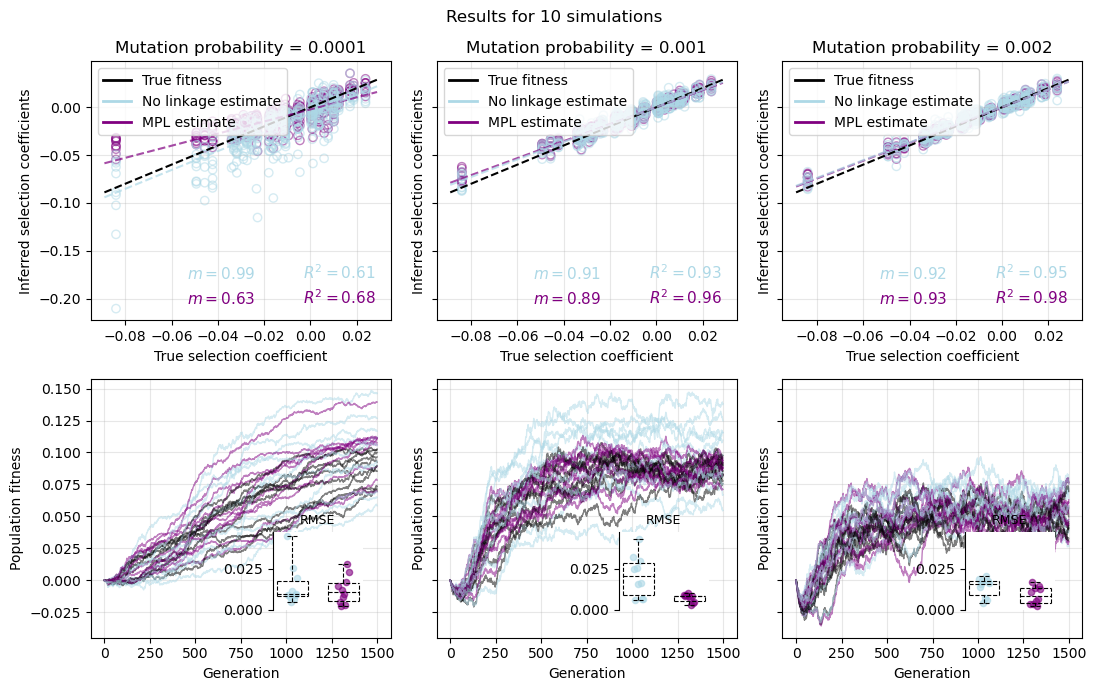

In [12]:
#Takes ~15 minutes
number_simulations = 10
population_size = 1000
number_sequences_per_time_point = population_size
mutation_probability_ = [0.0001,0.001,0.002] #Symmetric mutation probability per locus per generation
generations = 1500 #Total number of replication generations to simulate


#Plot results
fig, axes = plt.subplots(2,3,figsize=(11,7))
axes[0, 1].sharex(axes[0, 0])
axes[0, 1].sharey(axes[0, 0])
axes[0, 2].sharex(axes[0, 0])
axes[0, 2].sharey(axes[0, 0])
axes[1, 1].sharex(axes[1, 0])
axes[1, 1].sharey(axes[1, 0])
axes[1, 2].sharex(axes[1, 0])
axes[1, 2].sharey(axes[1, 0])

ax_ins_0 = inset_axes(axes[1,0], width="30%", height="30%", loc='lower right', borderpad=2)
ax_ins_1 = inset_axes(axes[1,1], width="30%", height="30%", loc='lower right', borderpad=2)
ax_ins_2 = inset_axes(axes[1,2], width="30%", height="30%", loc='lower right', borderpad=2)
ax_ins_1.sharey(ax_ins_0)
ax_ins_2.sharey(ax_ins_1)
ax_ins = [ax_ins_0,ax_ins_1,ax_ins_2]

selection_coefficients_all = np.tile(selection_coefficients,number_simulations)
rmse = np.zeros((3,2,number_simulations))

for j in range(3):

    mutation_probability = mutation_probability_[j]

    s_MPL_all = []
    s_no_linkage_all = []

    for k in range(number_simulations):
        #Run simulation
        sequences, numbers = simulate_wf(population_size, mutation_probability, generations, loci, num_unique_seqs, selection_coefficients, time_between_samples, number_sequences_per_time_point)
        s_MPL, C_int = MPL_inference(sequences, numbers, loci, number_sequences_per_time_point, time_between_samples, mutation_probability, gamma)
        s_no_linkage = no_linkage_inference(sequences, numbers, loci, number_sequences_per_time_point, time_between_samples, mutation_probability)

        #Store s estimates
        s_MPL_all.append(s_MPL)
        s_no_linkage_all.append(s_no_linkage)
        
        
        #Calculate true population fitness
        pop_s = np.zeros(generations)
        for g in range(1,generations):
            pop_s[g] = ((sequences[g-1]*selection_coefficients).sum(axis=1) * numbers[g-1]).sum()/population_size
            
        #Calculate inferred population fitness
        x = np.zeros((loci,generations))
        for g in range(generations):
            x[:,g] = np.sum([seq*num for seq,num in zip(sequences[g],numbers[g])],axis=0)/population_size
        pop_s_no_linkage = (x * s_no_linkage[:, np.newaxis]).sum(axis=0)
        pop_s_MPL = (x * s_MPL[:, np.newaxis]).sum(axis=0)

        #Save RMSE
        rmse[j,0,k] = root_mean_squared_error(pop_s,pop_s_no_linkage)
        rmse[j,1,k] = root_mean_squared_error(pop_s,pop_s_MPL)

        #Plot population fitness
        axes[1,j].plot(np.arange(generations),pop_s,label='True population fitness',color='black',alpha=0.5,linewidth=1)
        axes[1,j].plot(np.arange(generations),pop_s_MPL,label='MPL estimate',color='purple',alpha=0.5,linewidth=1)
        axes[1,j].plot(np.arange(generations),pop_s_no_linkage,label='No linkage estimate',color='lightblue',alpha=0.5,linewidth=1)

    #Plot selection coefficient scatters
    axes[0,j].scatter(selection_coefficients_all, np.concat(s_MPL_all), label='MPL estimate',facecolors='none', edgecolors='purple',alpha=0.5)
    axes[0,j].scatter(selection_coefficients_all, np.concat(s_no_linkage_all), label='No linkage estimate', facecolors='none', edgecolors='lightblue',alpha=0.5)
    l = np.linspace(selection_coefficients.min()-0.005,selection_coefficients.max()+0.005,10)
    axes[0,j].plot(l,l,'--',color='black')

    #Plot linear regressions
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_MPL_all))
    axes[0,j].plot(l,m*l+c,'--',color='purple',alpha=0.7)
    axes[0,j].text(0.95,0.05,f'$R^2=${r**2:.2f}',color='purple',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    axes[0,j].text(0.55,0.05,f'$m=${m:.2f}',color='purple',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_no_linkage_all))
    axes[0,j].plot(l,m*l+c,'--',color='lightblue',alpha=0.7)
    axes[0,j].text(0.95,0.15,f'$R^2=${r**2:.2f}',color='lightblue',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    axes[0,j].text(0.55,0.15,f'$m=${m:.2f}',color='lightblue',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')

    #Plot RMSE
    colours = ['lightblue','purple']

    for i in range(2):
        ax_ins[j].scatter(i+np.linspace(-0.1,0.1,number_simulations),rmse[j,i,:],s=20,marker='o',color=colours[i],alpha=0.6)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),np.median(rmse[j,i,:])+np.zeros(5),'--',color='black',linewidth=0.8)
        q1 = np.percentile(rmse[j,i,:],25)
        q2 = np.percentile(rmse[j,i,:],75)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q1+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q2+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)-0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)+0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(q2,rmse[j,i,:].max(),5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(rmse[j,i,:].min(),q1,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse[j,i,:].max()+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse[j,i,:].min()+np.zeros(5),'--',color='black',linewidth=0.8)


    #Format
    for i in range(2):
        axes[i,j].grid(alpha=0.3)
    axes[0,j].set_xlabel('True selection coefficient')
    axes[0,j].set_ylabel('Inferred selection coefficients')
    axes[1,j].set_xlabel('Generation')
    axes[1,j].set_ylabel('Population fitness')
    axes[0,j].set_title(f'Mutation probability = {mutation_probability}')
    ax_ins[j].set_title('RMSE',fontsize=9)
    ax_ins[j].spines['top'].set_visible(False)
    ax_ins[j].spines['right'].set_visible(False)
    ax_ins[j].spines['bottom'].set_visible(False)
    ax_ins[j].set_xticks([])

    #Legend
    custom_lines = [Line2D([0], [0], color='black', lw=2),
                    Line2D([0], [0], color='lightblue', lw=2),
                    Line2D([0], [0], color='purple', lw=2)]

    axes[0,j].legend(custom_lines, ['True fitness', 'No linkage estimate', 'MPL estimate'],fontsize=10,loc='upper left')

plt.setp(axes[0,1].get_yticklabels(), visible=False)
plt.setp(axes[0,2].get_yticklabels(), visible=False)
plt.setp(axes[1,1].get_yticklabels(), visible=False)
plt.setp(axes[1,2].get_yticklabels(), visible=False)
plt.suptitle(f'Results for {number_simulations} simulations')
plt.tight_layout()
plt.savefig(fig_path + f"/simulations_changing_mutation_probability.pdf")
plt.show()

For higher mutation probabilities (mu>>1/N, also an assumption of MPL), selection is greater than drift and so fitnesses can be estimated more accurately.

For too high a mutation probability it seems the whole thing breaks (though maybe is because of the additive fitness assumption)

## Change trajectory length

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_93258/3934281962.py:131: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


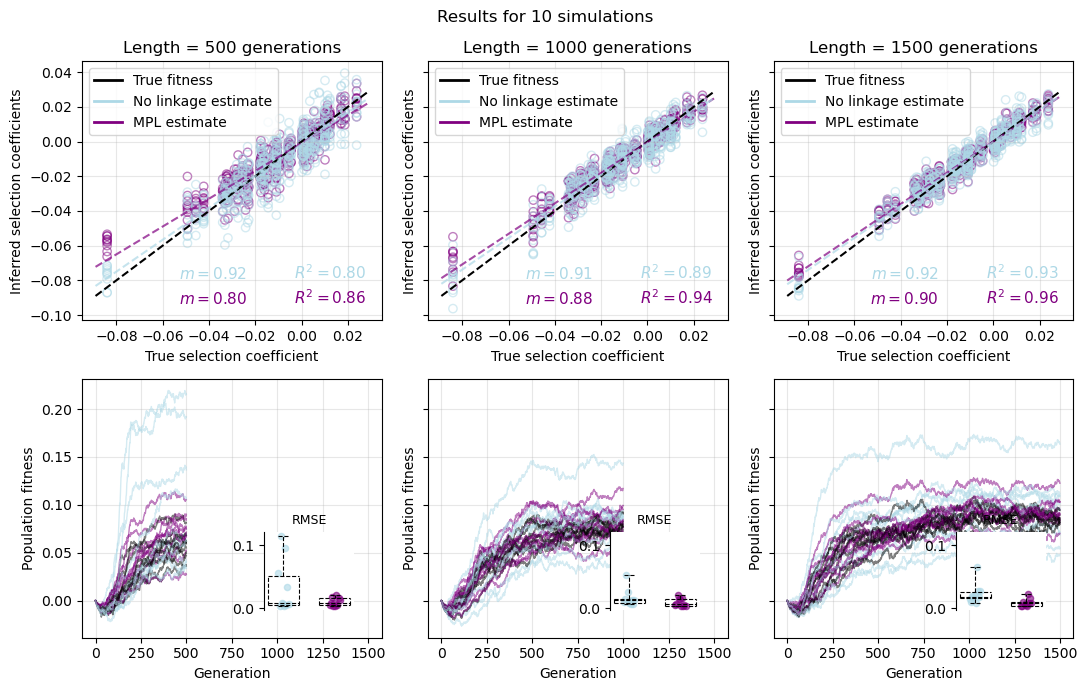

In [13]:
#Takes ~7 minutes
number_simulations = 10
population_size = 1000
number_sequences_per_time_point = population_size
mutation_probability = 0.001 #Symmetric mutation probability per locus per generation
generations_ = [500,1000,1500] #Total number of replication generations to simulate


#Plot results
fig, axes = plt.subplots(2,3,figsize=(11,7))
axes[0, 1].sharex(axes[0, 0])
axes[0, 1].sharey(axes[0, 0])
axes[0, 2].sharex(axes[0, 0])
axes[0, 2].sharey(axes[0, 0])
axes[1, 1].sharex(axes[1, 0])
axes[1, 1].sharey(axes[1, 0])
axes[1, 2].sharex(axes[1, 0])
axes[1, 2].sharey(axes[1, 0])

ax_ins_0 = inset_axes(axes[1,0], width="30%", height="30%", loc='lower right', borderpad=2)
ax_ins_1 = inset_axes(axes[1,1], width="30%", height="30%", loc='lower right', borderpad=2)
ax_ins_2 = inset_axes(axes[1,2], width="30%", height="30%", loc='lower right', borderpad=2)
ax_ins_1.sharey(ax_ins_0)
ax_ins_2.sharey(ax_ins_1)
ax_ins = [ax_ins_0,ax_ins_1,ax_ins_2]

selection_coefficients_all = np.tile(selection_coefficients,number_simulations)
rmse = np.zeros((3,2,number_simulations))

for j in range(3):

    generations = generations_[j]

    s_MPL_all = []
    s_no_linkage_all = []

    for k in range(number_simulations):
        #Run simulation
        sequences, numbers = simulate_wf(population_size, mutation_probability, generations, loci, num_unique_seqs, selection_coefficients, time_between_samples, number_sequences_per_time_point)
        s_MPL, C_int = MPL_inference(sequences, numbers, loci, number_sequences_per_time_point, time_between_samples, mutation_probability, gamma)
        s_no_linkage = no_linkage_inference(sequences, numbers, loci, number_sequences_per_time_point, time_between_samples, mutation_probability)

        #Store s estimates
        s_MPL_all.append(s_MPL)
        s_no_linkage_all.append(s_no_linkage)
        
        
        #Calculate true population fitness
        pop_s = np.zeros(generations)
        for g in range(1,generations):
            pop_s[g] = ((sequences[g-1]*selection_coefficients).sum(axis=1) * numbers[g-1]).sum()/population_size
            
        #Calculate inferred population fitness
        x = np.zeros((loci,generations))
        for g in range(generations):
            x[:,g] = np.sum([seq*num for seq,num in zip(sequences[g],numbers[g])],axis=0)/population_size
        pop_s_no_linkage = (x * s_no_linkage[:, np.newaxis]).sum(axis=0)
        pop_s_MPL = (x * s_MPL[:, np.newaxis]).sum(axis=0)

        #Save RMSE
        rmse[j,0,k] = root_mean_squared_error(pop_s,pop_s_no_linkage)
        rmse[j,1,k] = root_mean_squared_error(pop_s,pop_s_MPL)

        #Plot population fitness
        axes[1,j].plot(np.arange(generations),pop_s,label='True population fitness',color='black',alpha=0.5,linewidth=1)
        axes[1,j].plot(np.arange(generations),pop_s_MPL,label='MPL estimate',color='purple',alpha=0.5,linewidth=1)
        axes[1,j].plot(np.arange(generations),pop_s_no_linkage,label='No linkage estimate',color='lightblue',alpha=0.5,linewidth=1)

    #Plot selection coefficient scatters
    axes[0,j].scatter(selection_coefficients_all, np.concat(s_MPL_all), label='MPL estimate',facecolors='none', edgecolors='purple',alpha=0.5)
    axes[0,j].scatter(selection_coefficients_all, np.concat(s_no_linkage_all), label='No linkage estimate', facecolors='none', edgecolors='lightblue',alpha=0.5)
    l = np.linspace(selection_coefficients.min()-0.005,selection_coefficients.max()+0.005,10)
    axes[0,j].plot(l,l,'--',color='black')

    #Plot linear regressions
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_MPL_all))
    axes[0,j].plot(l,m*l+c,'--',color='purple',alpha=0.7)
    axes[0,j].text(0.95,0.05,f'$R^2=${r**2:.2f}',color='purple',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    axes[0,j].text(0.55,0.05,f'$m=${m:.2f}',color='purple',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_no_linkage_all))
    axes[0,j].plot(l,m*l+c,'--',color='lightblue',alpha=0.7)
    axes[0,j].text(0.95,0.15,f'$R^2=${r**2:.2f}',color='lightblue',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    axes[0,j].text(0.55,0.15,f'$m=${m:.2f}',color='lightblue',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')

    #Plot RMSE
    colours = ['lightblue','purple']

    for i in range(2):
        ax_ins[j].scatter(i+np.linspace(-0.1,0.1,number_simulations),rmse[j,i,:],s=20,marker='o',color=colours[i],alpha=0.6)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),np.median(rmse[j,i,:])+np.zeros(5),'--',color='black',linewidth=0.8)
        q1 = np.percentile(rmse[j,i,:],25)
        q2 = np.percentile(rmse[j,i,:],75)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q1+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q2+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)-0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)+0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(q2,rmse[j,i,:].max(),5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(rmse[j,i,:].min(),q1,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse[j,i,:].max()+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse[j,i,:].min()+np.zeros(5),'--',color='black',linewidth=0.8)


    #Format
    for i in range(2):
        axes[i,j].grid(alpha=0.3)
    axes[0,j].set_xlabel('True selection coefficient')
    axes[0,j].set_ylabel('Inferred selection coefficients')
    axes[1,j].set_xlabel('Generation')
    axes[1,j].set_ylabel('Population fitness')
    axes[0,j].set_title(f'Length = {generations} generations')
    ax_ins[j].set_title('RMSE',fontsize=9)
    ax_ins[j].spines['top'].set_visible(False)
    ax_ins[j].spines['right'].set_visible(False)
    ax_ins[j].spines['bottom'].set_visible(False)
    ax_ins[j].set_xticks([])

    #Legend
    custom_lines = [Line2D([0], [0], color='black', lw=2),
                    Line2D([0], [0], color='lightblue', lw=2),
                    Line2D([0], [0], color='purple', lw=2)]

    axes[0,j].legend(custom_lines, ['True fitness', 'No linkage estimate', 'MPL estimate'],fontsize=10,loc='upper left')

plt.setp(axes[0,1].get_yticklabels(), visible=False)
plt.setp(axes[0,2].get_yticklabels(), visible=False)
plt.setp(axes[1,1].get_yticklabels(), visible=False)
plt.setp(axes[1,2].get_yticklabels(), visible=False)
plt.suptitle(f'Results for {number_simulations} simulations')
plt.savefig(fig_path + f"/simulations_changing_trajectory_length.pdf")
plt.tight_layout()
plt.show()

For trajectories more than 1000 generations (once the population fitness has begun to plateau), the selection estimates are more accurate than shorter trajectories, which makes sense as longer trajectories supply more information. However, after the plateau, increasing the length further does not seem to improve the estimates significantly.

## Change number of loci

In [119]:
#Takes ~18 minutes
number_simulations = 10
population_size = 1000 #Total number of evolving sequences
number_sequences_per_time_point = population_size
mutation_probability = 0.001 #Symmetric mutation probability per locus per generation
generations = 1500 #Total number of replication generations to simulate
loci_ = [10,50,100] #Number of loci on the genome

rmse_loci = np.zeros((3,2,number_simulations))
pop_s_loci = np.zeros((3,number_simulations,generations))
pop_s_no_linkage_loci = np.zeros((3,number_simulations,generations))
pop_s_MPL_loci = np.zeros((3,number_simulations,generations))
s_MPL_all_loci = np.zeros((3,number_simulations,100))
s_no_linkage_all_loci = np.zeros((3,number_simulations,100))

for j in range(3):

    loci = loci_[j]
    samples = dist.rvs(size=loci)
    selection_coefficients = np.sort(samples/100)
    selection_coefficients_all = np.tile(selection_coefficients,number_simulations)

    for k in range(number_simulations):
        #Run simulation
        sequences, numbers = simulate_wf(population_size, mutation_probability, generations, loci, num_unique_seqs, selection_coefficients, time_between_samples, number_sequences_per_time_point)
        s_MPL, C_int = MPL_inference(sequences, numbers, loci, number_sequences_per_time_point, time_between_samples, mutation_probability, gamma)
        s_no_linkage = no_linkage_inference(sequences, numbers, loci, number_sequences_per_time_point, time_between_samples, mutation_probability)

        #Store s estimates
        s_MPL_all_loci[j,k,:loci] = s_MPL
        s_no_linkage_all_loci[j,k,:loci] = s_no_linkage
        
        #Calculate true population fitness
        for g in range(1,generations):
            pop_s_loci[j,k,g] = ((sequences[g-1]*selection_coefficients).sum(axis=1) * numbers[g-1]).sum()/population_size
            
        #Calculate inferred population fitness
        x = np.zeros((loci,generations))
        for g in range(generations):
            x[:,g] = np.sum([seq*num for seq,num in zip(sequences[g],numbers[g])],axis=0)/population_size
        pop_s_no_linkage_loci[j,k,:] = (x * s_no_linkage[:, np.newaxis]).sum(axis=0)
        pop_s_MPL_loci[j,k,:] = (x * s_MPL[:, np.newaxis]).sum(axis=0)

        #Save RMSE
        rmse_loci[j,0,k] = root_mean_squared_error(pop_s_loci[j,k,:],pop_s_no_linkage_loci[j,k,:])
        rmse_loci[j,1,k] = root_mean_squared_error(pop_s_loci[j,k,:],pop_s_MPL_loci[j,k,:])


/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_53990/1803560520.py:93: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


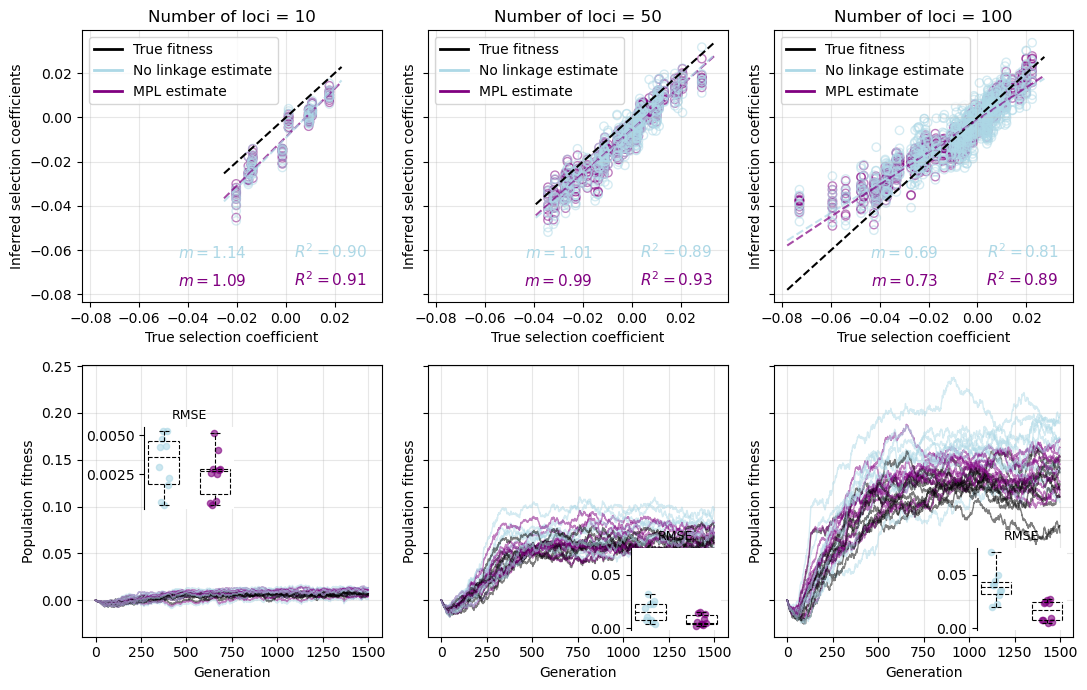

In [120]:
#Plot results
fig, axes = plt.subplots(2,3,figsize=(11,7))
axes[0, 1].sharex(axes[0, 0])
axes[0, 1].sharey(axes[0, 0])
axes[0, 2].sharex(axes[0, 0])
axes[0, 2].sharey(axes[0, 0])
axes[1, 1].sharex(axes[1, 0])
axes[1, 1].sharey(axes[1, 0])
axes[1, 2].sharex(axes[1, 0])
axes[1, 2].sharey(axes[1, 0])

ax_ins_0 = inset_axes(axes[1,0], width="30%", height="30%", loc='upper left', borderpad=4.5)
ax_ins_1 = inset_axes(axes[1,1], width="30%", height="30%", loc='lower right', borderpad=0.5)
ax_ins_2 = inset_axes(axes[1,2], width="30%", height="30%", loc='lower right', borderpad=0.5)
ax_ins_2.sharey(ax_ins_1)
ax_ins = [ax_ins_0,ax_ins_1,ax_ins_2]

for j in range(3):

    loci = loci_[j]
    samples = dist.rvs(size=loci)
    selection_coefficients = np.sort(samples/100)
    selection_coefficients_all = np.tile(selection_coefficients,number_simulations)

    for k in range(number_simulations):

        #Plot population fitness
        axes[1,j].plot(np.arange(generations),pop_s_loci[j,k,:],label='True population fitness',color='black',alpha=0.5,linewidth=1)
        axes[1,j].plot(np.arange(generations),pop_s_MPL_loci[j,k,:],label='MPL estimate',color='purple',alpha=0.5,linewidth=1)
        axes[1,j].plot(np.arange(generations),pop_s_no_linkage_loci[j,k,:],label='No linkage estimate',color='lightblue',alpha=0.5,linewidth=1)

    #Plot selection coefficient scatters
    axes[0,j].scatter(selection_coefficients_all, np.concat(s_MPL_all_loci[j,:,:loci]), label='MPL estimate',facecolors='none', edgecolors='purple',alpha=0.5)
    axes[0,j].scatter(selection_coefficients_all, np.concat(s_no_linkage_all_loci[j,:,:loci]), label='No linkage estimate', facecolors='none', edgecolors='lightblue',alpha=0.5)
    l = np.linspace(selection_coefficients.min()-0.005,selection_coefficients.max()+0.005,10)
    axes[0,j].plot(l,l,'--',color='black')

    #Plot linear regressions
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_MPL_all_loci[j,:,:loci]))
    axes[0,j].plot(l,m*l+c,'--',color='purple',alpha=0.7)
    axes[0,j].text(0.95,0.05,f'$R^2=${r**2:.2f}',color='purple',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    axes[0,j].text(0.55,0.05,f'$m=${m:.2f}',color='purple',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_no_linkage_all_loci[j,:,:loci]))
    axes[0,j].plot(l,m*l+c,'--',color='lightblue',alpha=0.7)
    axes[0,j].text(0.95,0.15,f'$R^2=${r**2:.2f}',color='lightblue',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    axes[0,j].text(0.55,0.15,f'$m=${m:.2f}',color='lightblue',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')

    #Plot RMSE
    colours = ['lightblue','purple']

    for i in range(2):
        ax_ins[j].scatter(i+np.linspace(-0.1,0.1,number_simulations),rmse_loci[j,i,:],s=20,marker='o',color=colours[i],alpha=0.6)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),np.median(rmse_loci[j,i,:])+np.zeros(5),'--',color='black',linewidth=0.8)
        q1 = np.percentile(rmse_loci[j,i,:],25)
        q2 = np.percentile(rmse_loci[j,i,:],75)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q1+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q2+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)-0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)+0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(q2,rmse_loci[j,i,:].max(),5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(rmse_loci[j,i,:].min(),q1,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse_loci[j,i,:].max()+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse_loci[j,i,:].min()+np.zeros(5),'--',color='black',linewidth=0.8)


    #Format
    for i in range(2):
        axes[i,j].grid(alpha=0.3)
    axes[0,j].set_xlabel('True selection coefficient')
    axes[0,j].set_ylabel('Inferred selection coefficients')
    axes[1,j].set_xlabel('Generation')
    axes[1,j].set_ylabel('Population fitness')
    axes[0,j].set_title(f'Number of loci = {loci}')
    ax_ins[j].set_title('RMSE',fontsize=9)
    ax_ins[j].spines['top'].set_visible(False)
    ax_ins[j].spines['right'].set_visible(False)
    ax_ins[j].spines['bottom'].set_visible(False)
    ax_ins[j].set_xticks([])

    #Legend
    custom_lines = [Line2D([0], [0], color='black', lw=2),
                    Line2D([0], [0], color='lightblue', lw=2),
                    Line2D([0], [0], color='purple', lw=2)]

    axes[0,j].legend(custom_lines, ['True fitness', 'No linkage estimate', 'MPL estimate'],fontsize=10,loc='upper left')

plt.setp(axes[0,1].get_yticklabels(), visible=False)
plt.setp(axes[0,2].get_yticklabels(), visible=False)
plt.setp(axes[1,1].get_yticklabels(), visible=False)
plt.setp(axes[1,2].get_yticklabels(), visible=False)
# plt.suptitle(f'Results for {number_simulations} simulations')
plt.tight_layout()
plt.savefig(fig_path + f"/simulations_changing_number_loci.pdf")
plt.show()

As the number of loci increases, the bias of the estimates (underestimation of magnitudes) gets slightly worse, though the precision improves . The total population fitness increases, and the RMSE increases, but the percentage error does not (?). Perhaps the estimates get worse due to more clonal interference with more loci (and so more competing genotypes)

## Change selection coefficients

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_93258/4014542281.py:132: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


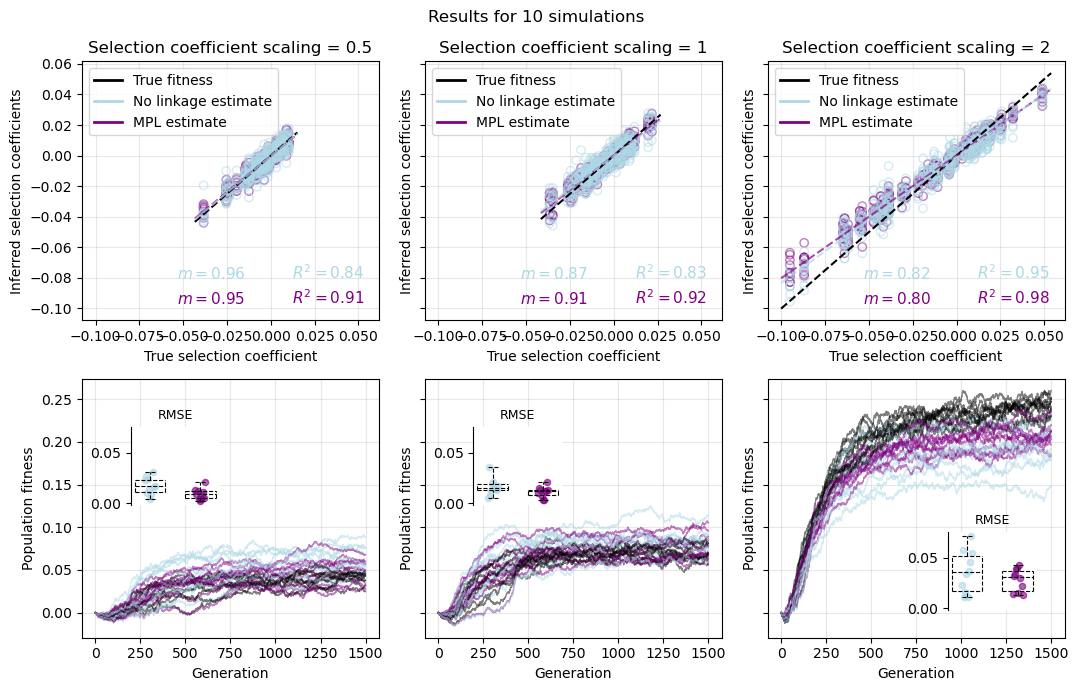

In [15]:
#Takes ~11 minutes
number_simulations = 10
population_size = 1000 #Total number of evolving sequences
mutation_probability = 0.001 #Symmetric mutation probability per locus per generation
generations = 1500 #Total number of replication generations to simulate
loci = 50 #Number of loci on the genome
s_scaling_ = [0.5,1,2]

#Plot results
fig, axes = plt.subplots(2,3,figsize=(11,7))
axes[0, 1].sharex(axes[0, 0])
axes[0, 1].sharey(axes[0, 0])
axes[0, 2].sharex(axes[0, 0])
axes[0, 2].sharey(axes[0, 0])
axes[1, 1].sharex(axes[1, 0])
axes[1, 1].sharey(axes[1, 0])
axes[1, 2].sharex(axes[1, 0])
axes[1, 2].sharey(axes[1, 0])

ax_ins_0 = inset_axes(axes[1,0], width="30%", height="30%", loc='upper left', borderpad=3.5)
ax_ins_1 = inset_axes(axes[1,1], width="30%", height="30%", loc='upper left', borderpad=3.5)
ax_ins_2 = inset_axes(axes[1,2], width="30%", height="30%", loc='lower right', borderpad=2)
ax_ins_1.sharey(ax_ins_0)
ax_ins_2.sharey(ax_ins_1)
ax_ins = [ax_ins_0,ax_ins_1,ax_ins_2]

rmse = np.zeros((3,2,number_simulations))

for j in range(3):

    samples = dist.rvs(size=loci)
    selection_coefficients = np.sort(samples/100)
    selection_coefficients = selection_coefficients*s_scaling_[j]
    selection_coefficients_all = np.tile(selection_coefficients,number_simulations)

    s_MPL_all = []
    s_no_linkage_all = []

    for k in range(number_simulations):
        #Run simulation
        sequences, numbers = simulate_wf(population_size, mutation_probability, generations, loci, num_unique_seqs, selection_coefficients, time_between_samples, number_sequences_per_time_point)
        s_MPL, C_int = MPL_inference(sequences, numbers, loci, number_sequences_per_time_point, time_between_samples, mutation_probability, gamma)
        s_no_linkage = no_linkage_inference(sequences, numbers, loci, number_sequences_per_time_point, time_between_samples, mutation_probability)

        #Store s estimates
        s_MPL_all.append(s_MPL)
        s_no_linkage_all.append(s_no_linkage)
        
        
        #Calculate true population fitness
        pop_s = np.zeros(generations)
        for g in range(1,generations):
            pop_s[g] = ((sequences[g-1]*selection_coefficients).sum(axis=1) * numbers[g-1]).sum()/population_size
            
        #Calculate inferred population fitness
        x = np.zeros((loci,generations))
        for g in range(generations):
            x[:,g] = np.sum([seq*num for seq,num in zip(sequences[g],numbers[g])],axis=0)/population_size
        pop_s_no_linkage = (x * s_no_linkage[:, np.newaxis]).sum(axis=0)
        pop_s_MPL = (x * s_MPL[:, np.newaxis]).sum(axis=0)

        #Save RMSE
        rmse[j,0,k] = root_mean_squared_error(pop_s,pop_s_no_linkage)
        rmse[j,1,k] = root_mean_squared_error(pop_s,pop_s_MPL)

        #Plot population fitness
        axes[1,j].plot(np.arange(generations),pop_s,label='True population fitness',color='black',alpha=0.5,linewidth=1)
        axes[1,j].plot(np.arange(generations),pop_s_MPL,label='MPL estimate',color='purple',alpha=0.5,linewidth=1)
        axes[1,j].plot(np.arange(generations),pop_s_no_linkage,label='No linkage estimate',color='lightblue',alpha=0.5,linewidth=1)

    #Plot selection coefficient scatters
    axes[0,j].scatter(selection_coefficients_all, np.concat(s_MPL_all), label='MPL estimate',facecolors='none', edgecolors='purple',alpha=0.5)
    axes[0,j].scatter(selection_coefficients_all, np.concat(s_no_linkage_all), label='No linkage estimate', facecolors='none', edgecolors='lightblue',alpha=0.5)
    l = np.linspace(selection_coefficients.min()-0.005,selection_coefficients.max()+0.005,10)
    axes[0,j].plot(l,l,'--',color='black')

    #Plot linear regressions
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_MPL_all))
    axes[0,j].plot(l,m*l+c,'--',color='purple',alpha=0.7)
    axes[0,j].text(0.95,0.05,f'$R^2=${r**2:.2f}',color='purple',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    axes[0,j].text(0.55,0.05,f'$m=${m:.2f}',color='purple',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_no_linkage_all))
    axes[0,j].plot(l,m*l+c,'--',color='lightblue',alpha=0.7)
    axes[0,j].text(0.95,0.15,f'$R^2=${r**2:.2f}',color='lightblue',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    axes[0,j].text(0.55,0.15,f'$m=${m:.2f}',color='lightblue',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')

    #Plot RMSE
    colours = ['lightblue','purple']

    for i in range(2):
        ax_ins[j].scatter(i+np.linspace(-0.1,0.1,number_simulations),rmse[j,i,:],s=20,marker='o',color=colours[i],alpha=0.6)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),np.median(rmse[j,i,:])+np.zeros(5),'--',color='black',linewidth=0.8)
        q1 = np.percentile(rmse[j,i,:],25)
        q2 = np.percentile(rmse[j,i,:],75)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q1+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q2+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)-0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)+0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(q2,rmse[j,i,:].max(),5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(rmse[j,i,:].min(),q1,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse[j,i,:].max()+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse[j,i,:].min()+np.zeros(5),'--',color='black',linewidth=0.8)


    #Format
    for i in range(2):
        axes[i,j].grid(alpha=0.3)
    axes[0,j].set_xlabel('True selection coefficient')
    axes[0,j].set_ylabel('Inferred selection coefficients')
    axes[1,j].set_xlabel('Generation')
    axes[1,j].set_ylabel('Population fitness')
    axes[0,j].set_title(f'Selection coefficient scaling = {s_scaling_[j]}')
    ax_ins[j].set_title('RMSE',fontsize=9)
    ax_ins[j].spines['top'].set_visible(False)
    ax_ins[j].spines['right'].set_visible(False)
    ax_ins[j].spines['bottom'].set_visible(False)
    ax_ins[j].set_xticks([])

    #Legend
    custom_lines = [Line2D([0], [0], color='black', lw=2),
                    Line2D([0], [0], color='lightblue', lw=2),
                    Line2D([0], [0], color='purple', lw=2)]

    axes[0,j].legend(custom_lines, ['True fitness', 'No linkage estimate', 'MPL estimate'],fontsize=10,loc='upper left')

plt.setp(axes[0,1].get_yticklabels(), visible=False)
plt.setp(axes[0,2].get_yticklabels(), visible=False)
plt.setp(axes[1,1].get_yticklabels(), visible=False)
plt.setp(axes[1,2].get_yticklabels(), visible=False)
plt.suptitle(f'Results for {number_simulations} simulations')
plt.tight_layout()
plt.savefig(fig_path + f"/simulations_changing_selection_coefficients.pdf")
plt.show()

It seems as the selection coefficients increase, the RMSE increases in absolute terms, but the percentage error decreases. It seems that the estimates become more precise, but that the bias to underestimate the magnitude of selection increases.
With greater selection coefficients, there is a larger difference between the fitnesses of genotypes, causing selection to happen quicker. If selection is too quick, the magnitude of fitnesses will be underestimated. This is mentioned in Sohail et al. 2020, where they note that s will be underestimated for variants that arise and fix between two sampling events.

## Change number of loci, keeping total fitness constant

In [121]:
#Takes ~18 minutes
number_simulations = 10
population_size = 1000 #Total number of evolving sequences
number_sequences_per_time_point = population_size
mutation_probability = 0.001 #Symmetric mutation probability per locus per generation
generations = 1500 #Total number of replication generations to simulate
loci_ = [10,50,100] #Number of loci on the genome


rmse_loci_fix_s = np.zeros((3,2,number_simulations))
pop_s_loci_fix_s = np.zeros((3,number_simulations,generations))
pop_s_no_linkage_loci_fix_s = np.zeros((3,number_simulations,generations))
pop_s_MPL_loci_fix_s = np.zeros((3,number_simulations,generations))
s_MPL_all_loci_fix_s = np.zeros((3,number_simulations,loci))
s_no_linkage_all_loci_fix_s = np.zeros((3,number_simulations,loci))


for j in range(3):

    loci = loci_[j]
    samples = dist.rvs(size=loci)
    selection_coefficients = np.sort(samples/100)*50/loci
    selection_coefficients_all = np.tile(selection_coefficients,number_simulations)

    for k in range(number_simulations):
        #Run simulation
        sequences, numbers = simulate_wf(population_size, mutation_probability, generations, loci, num_unique_seqs, selection_coefficients, time_between_samples, number_sequences_per_time_point)
        s_MPL, C_int = MPL_inference(sequences, numbers, loci, number_sequences_per_time_point, time_between_samples, mutation_probability, gamma)
        s_no_linkage = no_linkage_inference(sequences, numbers, loci, number_sequences_per_time_point, time_between_samples, mutation_probability)

        #Store s estimates
        s_MPL_all_loci_fix_s[j,k,:loci] = s_MPL
        s_no_linkage_all_loci_fix_s[j,k,:loci] = s_no_linkage
        
        #Calculate true population fitness
        for g in range(1,generations):
            pop_s_loci_fix_s[j,k,g] = ((sequences[g-1]*selection_coefficients).sum(axis=1) * numbers[g-1]).sum()/population_size
            
        #Calculate inferred population fitness
        x = np.zeros((loci,generations))
        for g in range(generations):
            x[:,g] = np.sum([seq*num for seq,num in zip(sequences[g],numbers[g])],axis=0)/population_size
        pop_s_no_linkage_loci_fix_s[j,k,:] = (x * s_no_linkage[:, np.newaxis]).sum(axis=0)
        pop_s_MPL_loci_fix_s[j,k,:] = (x * s_MPL[:, np.newaxis]).sum(axis=0)

        #Save RMSE
        rmse_loci_fix_s[j,0,k] = root_mean_squared_error(pop_s_loci_fix_s[j,k,:],pop_s_no_linkage_loci_fix_s[j,k,:])
        rmse_loci_fix_s[j,1,k] = root_mean_squared_error(pop_s_loci_fix_s[j,k,:],pop_s_MPL_loci_fix_s[j,k,:])


/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_53990/1948139553.py:92: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


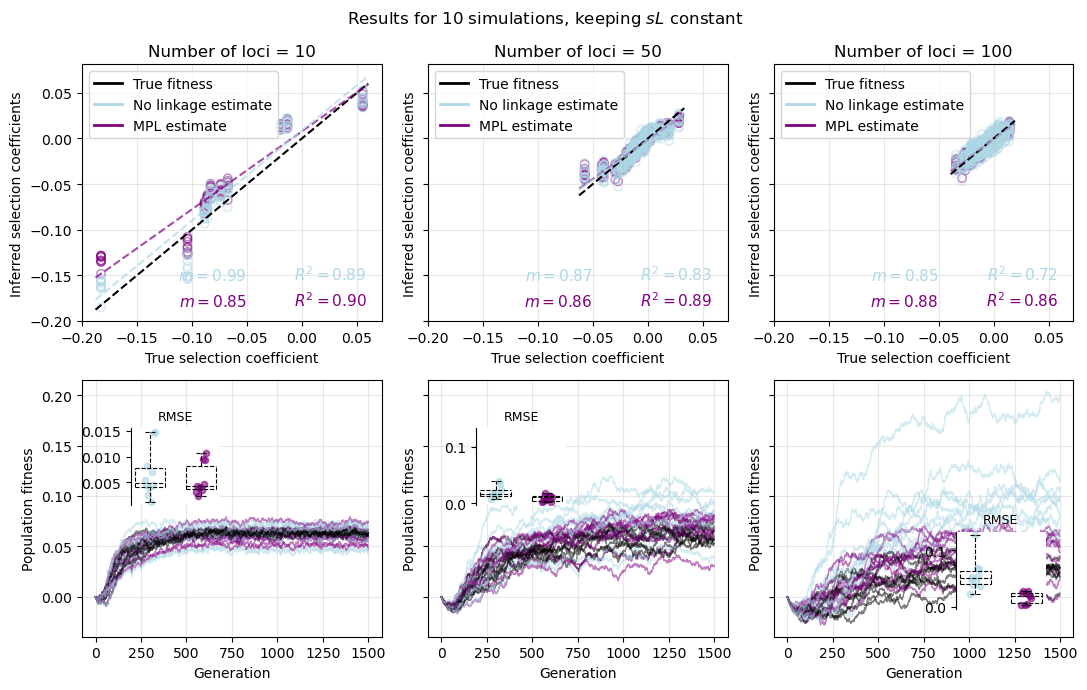

In [122]:
#Plot results
fig, axes = plt.subplots(2,3,figsize=(11,7))
axes[0, 1].sharex(axes[0, 0])
axes[0, 1].sharey(axes[0, 0])
axes[0, 2].sharex(axes[0, 0])
axes[0, 2].sharey(axes[0, 0])
axes[1, 1].sharex(axes[1, 0])
axes[1, 1].sharey(axes[1, 0])
axes[1, 2].sharex(axes[1, 0])
axes[1, 2].sharey(axes[1, 0])

ax_ins_0 = inset_axes(axes[1,0], width="30%", height="30%", loc='upper left', borderpad=3.5)
ax_ins_1 = inset_axes(axes[1,1], width="30%", height="30%", loc='upper left', borderpad=3.5)
ax_ins_2 = inset_axes(axes[1,2], width="30%", height="30%", loc='lower right', borderpad=2)
ax_ins_2.sharey(ax_ins_1)
ax_ins = [ax_ins_0,ax_ins_1,ax_ins_2]

for j in range(3):

    loci = loci_[j]
    samples = dist.rvs(size=loci)
    selection_coefficients = np.sort(samples/100)*50/loci
    selection_coefficients_all = np.tile(selection_coefficients,number_simulations)

    for k in range(number_simulations):
        #Plot population fitness
        axes[1,j].plot(np.arange(generations),pop_s_loci_fix_s[j,k,:],label='True population fitness',color='black',alpha=0.5,linewidth=1)
        axes[1,j].plot(np.arange(generations),pop_s_MPL_loci_fix_s[j,k,:],label='MPL estimate',color='purple',alpha=0.5,linewidth=1)
        axes[1,j].plot(np.arange(generations),pop_s_no_linkage_loci_fix_s[j,k,:],label='No linkage estimate',color='lightblue',alpha=0.5,linewidth=1)

    #Plot selection coefficient scatters
    axes[0,j].scatter(selection_coefficients_all, np.concat(s_MPL_all_loci_fix_s[j,:,:loci]), label='MPL estimate',facecolors='none', edgecolors='purple',alpha=0.5)
    axes[0,j].scatter(selection_coefficients_all, np.concat(s_no_linkage_all_loci_fix_s[j,:,:loci]), label='No linkage estimate', facecolors='none', edgecolors='lightblue',alpha=0.5)
    l = np.linspace(selection_coefficients.min()-0.005,selection_coefficients.max()+0.005,10)
    axes[0,j].plot(l,l,'--',color='black')

    #Plot linear regressions
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_MPL_all_loci_fix_s[j,:,:loci]))
    axes[0,j].plot(l,m*l+c,'--',color='purple',alpha=0.7)
    axes[0,j].text(0.95,0.05,f'$R^2=${r**2:.2f}',color='purple',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    axes[0,j].text(0.55,0.05,f'$m=${m:.2f}',color='purple',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_no_linkage_all_loci_fix_s[j,:,:loci]))
    axes[0,j].plot(l,m*l+c,'--',color='lightblue',alpha=0.7)
    axes[0,j].text(0.95,0.15,f'$R^2=${r**2:.2f}',color='lightblue',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    axes[0,j].text(0.55,0.15,f'$m=${m:.2f}',color='lightblue',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')

    #Plot RMSE
    colours = ['lightblue','purple']

    for i in range(2):
        ax_ins[j].scatter(i+np.linspace(-0.1,0.1,number_simulations),rmse_loci_fix_s[j,i,:],s=20,marker='o',color=colours[i],alpha=0.6)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),np.median(rmse_loci_fix_s[j,i,:])+np.zeros(5),'--',color='black',linewidth=0.8)
        q1 = np.percentile(rmse_loci_fix_s[j,i,:],25)
        q2 = np.percentile(rmse_loci_fix_s[j,i,:],75)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q1+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q2+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)-0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)+0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(q2,rmse_loci_fix_s[j,i,:].max(),5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(rmse_loci_fix_s[j,i,:].min(),q1,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse_loci_fix_s[j,i,:].max()+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse_loci_fix_s[j,i,:].min()+np.zeros(5),'--',color='black',linewidth=0.8)


    #Format
    for i in range(2):
        axes[i,j].grid(alpha=0.3)
    axes[0,j].set_xlabel('True selection coefficient')
    axes[0,j].set_ylabel('Inferred selection coefficients')
    axes[1,j].set_xlabel('Generation')
    axes[1,j].set_ylabel('Population fitness')
    axes[0,j].set_title(f'Number of loci = {loci}')
    ax_ins[j].set_title('RMSE',fontsize=9)
    ax_ins[j].spines['top'].set_visible(False)
    ax_ins[j].spines['right'].set_visible(False)
    ax_ins[j].spines['bottom'].set_visible(False)
    ax_ins[j].set_xticks([])

    #Legend
    custom_lines = [Line2D([0], [0], color='black', lw=2),
                    Line2D([0], [0], color='lightblue', lw=2),
                    Line2D([0], [0], color='purple', lw=2)]

    axes[0,j].legend(custom_lines, ['True fitness', 'No linkage estimate', 'MPL estimate'],fontsize=10,loc='upper left')

plt.setp(axes[0,1].get_yticklabels(), visible=False)
plt.setp(axes[0,2].get_yticklabels(), visible=False)
plt.setp(axes[1,1].get_yticklabels(), visible=False)
plt.setp(axes[1,2].get_yticklabels(), visible=False)
plt.suptitle(f'Results for {number_simulations} simulations, keeping $sL$ constant')
plt.tight_layout()
plt.savefig(fig_path + f"/simulations_changing_num_loci_and_selection_coeffs.pdf")
plt.show()

## Figure SI13

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_53990/500652225.py:183: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


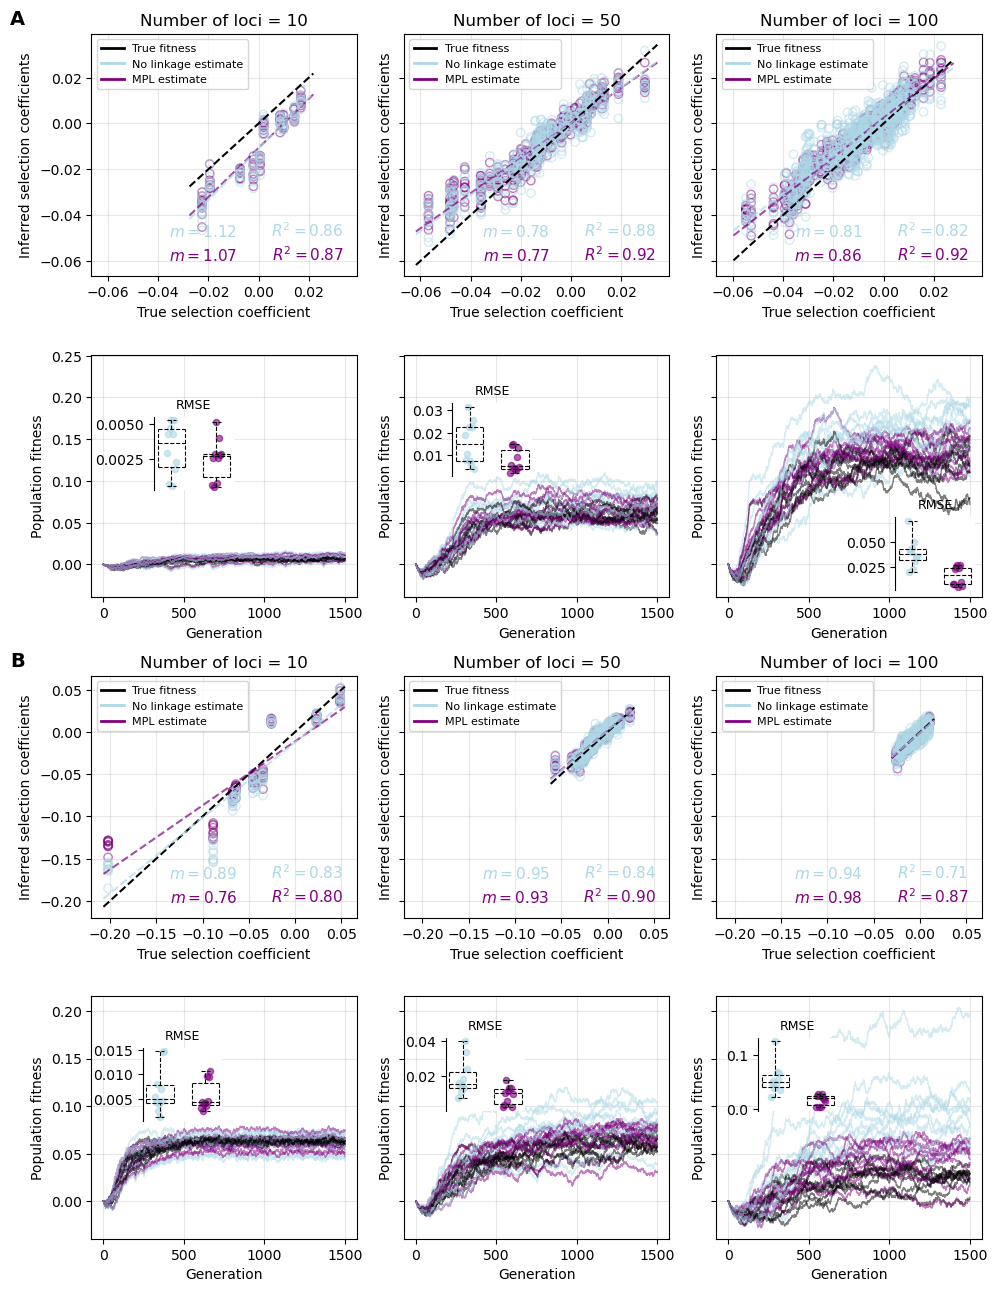

In [130]:
#Plot results
fig, axes = plt.subplots(4,3,figsize=(10,13))
axes[0, 1].sharex(axes[0, 0])
axes[0, 1].sharey(axes[0, 0])
axes[0, 2].sharex(axes[0, 0])
axes[0, 2].sharey(axes[0, 0])
axes[1, 1].sharex(axes[1, 0])
axes[1, 1].sharey(axes[1, 0])
axes[1, 2].sharex(axes[1, 0])
axes[1, 2].sharey(axes[1, 0])
axes[2, 1].sharex(axes[2, 0])
axes[2, 1].sharey(axes[2, 0])
axes[2, 2].sharex(axes[2, 0])
axes[2, 2].sharey(axes[2, 0])
axes[3, 1].sharex(axes[3, 0])
axes[3, 1].sharey(axes[3, 0])
axes[3, 2].sharex(axes[3, 0])
axes[3, 2].sharey(axes[3, 0])

ax_ins_0 = inset_axes(axes[1,0], width="30%", height="30%", loc='upper left', borderpad=4.5)
ax_ins_1 = inset_axes(axes[1,1], width="30%", height="30%", loc='upper left', borderpad=3.5)
ax_ins_2 = inset_axes(axes[1,2], width="30%", height="30%", loc='lower right', borderpad=0.5)
ax_ins_3 = inset_axes(axes[3,0], width="30%", height="30%", loc='upper left', borderpad=3.7)
ax_ins_4 = inset_axes(axes[3,1], width="30%", height="30%", loc='upper left', borderpad=3)
ax_ins_5 = inset_axes(axes[3,2], width="30%", height="30%", loc='upper left', borderpad=3)
ax_ins = [ax_ins_0,ax_ins_1,ax_ins_2,ax_ins_3,ax_ins_4,ax_ins_5]


#Changing number of loci
for j in range(3):

    loci = loci_[j]
    samples = dist.rvs(size=loci)
    selection_coefficients = np.sort(samples/100)
    selection_coefficients_all = np.tile(selection_coefficients,number_simulations)

    for k in range(number_simulations):

        #Plot population fitness
        axes[1,j].plot(np.arange(generations),pop_s_loci[j,k,:],label='True population fitness',color='black',alpha=0.5,linewidth=1)
        axes[1,j].plot(np.arange(generations),pop_s_MPL_loci[j,k,:],label='MPL estimate',color='purple',alpha=0.5,linewidth=1)
        axes[1,j].plot(np.arange(generations),pop_s_no_linkage_loci[j,k,:],label='No linkage estimate',color='lightblue',alpha=0.5,linewidth=1)

    #Plot selection coefficient scatters
    axes[0,j].scatter(selection_coefficients_all, np.concat(s_MPL_all_loci[j,:,:loci]), label='MPL estimate',facecolors='none', edgecolors='purple',alpha=0.5)
    axes[0,j].scatter(selection_coefficients_all, np.concat(s_no_linkage_all_loci[j,:,:loci]), label='No linkage estimate', facecolors='none', edgecolors='lightblue',alpha=0.5)
    l = np.linspace(selection_coefficients.min()-0.005,selection_coefficients.max()+0.005,10)
    axes[0,j].plot(l,l,'--',color='black')

    #Plot linear regressions
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_MPL_all_loci[j,:,:loci]))
    axes[0,j].plot(l,m*l+c,'--',color='purple',alpha=0.7)
    axes[0,j].text(0.95,0.05,f'$R^2=${r**2:.2f}',color='purple',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    axes[0,j].text(0.55,0.05,f'$m=${m:.2f}',color='purple',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_no_linkage_all_loci[j,:,:loci]))
    axes[0,j].plot(l,m*l+c,'--',color='lightblue',alpha=0.7)
    axes[0,j].text(0.95,0.15,f'$R^2=${r**2:.2f}',color='lightblue',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')
    axes[0,j].text(0.55,0.15,f'$m=${m:.2f}',color='lightblue',fontsize=11,transform=axes[0,j].transAxes, ha='right', va='bottom')

    #Plot RMSE
    colours = ['lightblue','purple']

    for i in range(2):
        ax_ins[j].scatter(i+np.linspace(-0.1,0.1,number_simulations),rmse_loci[j,i,:],s=20,marker='o',color=colours[i],alpha=0.6)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),np.median(rmse_loci[j,i,:])+np.zeros(5),'--',color='black',linewidth=0.8)
        q1 = np.percentile(rmse_loci[j,i,:],25)
        q2 = np.percentile(rmse_loci[j,i,:],75)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q1+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.3,0.3,5),q2+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)-0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5)+0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(q2,rmse_loci[j,i,:].max(),5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.zeros(5),np.linspace(rmse_loci[j,i,:].min(),q1,5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse_loci[j,i,:].max()+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[j].plot(i+np.linspace(-0.1,0.1,5),rmse_loci[j,i,:].min()+np.zeros(5),'--',color='black',linewidth=0.8)


    #Format
    for i in range(2):
        axes[i,j].grid(alpha=0.3)
    axes[0,j].set_xlabel('True selection coefficient')
    axes[0,j].set_ylabel('Inferred selection coefficients')
    axes[1,j].set_xlabel('Generation')
    axes[1,j].set_ylabel('Population fitness')
    axes[0,j].set_title(f'Number of loci = {loci}')
    ax_ins[j].set_title('RMSE',fontsize=9)
    ax_ins[j].spines['top'].set_visible(False)
    ax_ins[j].spines['right'].set_visible(False)
    ax_ins[j].spines['bottom'].set_visible(False)
    ax_ins[j].set_xticks([])

    #Legend
    custom_lines = [Line2D([0], [0], color='black', lw=2),
                    Line2D([0], [0], color='lightblue', lw=2),
                    Line2D([0], [0], color='purple', lw=2)]

    axes[0,j].legend(custom_lines, ['True fitness', 'No linkage estimate', 'MPL estimate'],fontsize=8,loc='upper left')

plt.setp(axes[0,1].get_yticklabels(), visible=False)
plt.setp(axes[0,2].get_yticklabels(), visible=False)
plt.setp(axes[1,1].get_yticklabels(), visible=False)
plt.setp(axes[1,2].get_yticklabels(), visible=False)
axes[0,0].text(-0.25, 1.1, 'A', transform=axes[0,0].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')


#Changing number of loci, sL constant
for j in range(3):

    loci = loci_[j]
    samples = dist.rvs(size=loci)
    selection_coefficients = np.sort(samples/100)*50/loci
    selection_coefficients_all = np.tile(selection_coefficients,number_simulations)

    for k in range(number_simulations):
        #Plot population fitness
        axes[3,j].plot(np.arange(generations),pop_s_loci_fix_s[j,k,:],label='True population fitness',color='black',alpha=0.5,linewidth=1)
        axes[3,j].plot(np.arange(generations),pop_s_MPL_loci_fix_s[j,k,:],label='MPL estimate',color='purple',alpha=0.5,linewidth=1)
        axes[3,j].plot(np.arange(generations),pop_s_no_linkage_loci_fix_s[j,k,:],label='No linkage estimate',color='lightblue',alpha=0.5,linewidth=1)

    #Plot selection coefficient scatters
    axes[2,j].scatter(selection_coefficients_all, np.concat(s_MPL_all_loci_fix_s[j,:,:loci]), label='MPL estimate',facecolors='none', edgecolors='purple',alpha=0.5)
    axes[2,j].scatter(selection_coefficients_all, np.concat(s_no_linkage_all_loci_fix_s[j,:,:loci]), label='No linkage estimate', facecolors='none', edgecolors='lightblue',alpha=0.5)
    l = np.linspace(selection_coefficients.min()-0.005,selection_coefficients.max()+0.005,10)
    axes[2,j].plot(l,l,'--',color='black')

    #Plot linear regressions
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_MPL_all_loci_fix_s[j,:,:loci]))
    axes[2,j].plot(l,m*l+c,'--',color='purple',alpha=0.7)
    axes[2,j].text(0.95,0.05,f'$R^2=${r**2:.2f}',color='purple',fontsize=11,transform=axes[2,j].transAxes, ha='right', va='bottom')
    axes[2,j].text(0.55,0.05,f'$m=${m:.2f}',color='purple',fontsize=11,transform=axes[2,j].transAxes, ha='right', va='bottom')
    
    m, c, r, p, std_err = stats.linregress(selection_coefficients_all, np.concat(s_no_linkage_all_loci_fix_s[j,:,:loci]))
    axes[2,j].plot(l,m*l+c,'--',color='lightblue',alpha=0.7)
    axes[2,j].text(0.95,0.15,f'$R^2=${r**2:.2f}',color='lightblue',fontsize=11,transform=axes[2,j].transAxes, ha='right', va='bottom')
    axes[2,j].text(0.55,0.15,f'$m=${m:.2f}',color='lightblue',fontsize=11,transform=axes[2,j].transAxes, ha='right', va='bottom')

    #Plot RMSE
    colours = ['lightblue','purple']

    for i in range(2):
        ax_ins[3+j].scatter(i+np.linspace(-0.1,0.1,number_simulations),rmse_loci_fix_s[j,i,:],s=20,marker='o',color=colours[i],alpha=0.6)
        ax_ins[3+j].plot(i+np.linspace(-0.3,0.3,5),np.median(rmse_loci_fix_s[j,i,:])+np.zeros(5),'--',color='black',linewidth=0.8)
        q1 = np.percentile(rmse_loci_fix_s[j,i,:],25)
        q2 = np.percentile(rmse_loci_fix_s[j,i,:],75)
        ax_ins[3+j].plot(i+np.linspace(-0.3,0.3,5),q1+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[3+j].plot(i+np.linspace(-0.3,0.3,5),q2+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[3+j].plot(i+np.zeros(5)-0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[3+j].plot(i+np.zeros(5)+0.3,np.linspace(q1,q2,5),'--',color='black',linewidth=0.8)
        ax_ins[3+j].plot(i+np.zeros(5),np.linspace(q2,rmse_loci_fix_s[j,i,:].max(),5),'--',color='black',linewidth=0.8)
        ax_ins[3+j].plot(i+np.zeros(5),np.linspace(rmse_loci_fix_s[j,i,:].min(),q1,5),'--',color='black',linewidth=0.8)
        ax_ins[3+j].plot(i+np.linspace(-0.1,0.1,5),rmse_loci_fix_s[j,i,:].max()+np.zeros(5),'--',color='black',linewidth=0.8)
        ax_ins[3+j].plot(i+np.linspace(-0.1,0.1,5),rmse_loci_fix_s[j,i,:].min()+np.zeros(5),'--',color='black',linewidth=0.8)


    #Format
    for i in range(2):
        axes[2+i,j].grid(alpha=0.3)
    axes[2,j].set_xlabel('True selection coefficient')
    axes[2,j].set_ylabel('Inferred selection coefficients')
    axes[3,j].set_xlabel('Generation')
    axes[3,j].set_ylabel('Population fitness')
    axes[2,j].set_title(f'Number of loci = {loci}')
    ax_ins[3+j].set_title('RMSE',fontsize=9)
    ax_ins[3+j].spines['top'].set_visible(False)
    ax_ins[3+j].spines['right'].set_visible(False)
    ax_ins[3+j].spines['bottom'].set_visible(False)
    ax_ins[3+j].set_xticks([])

    #Legend
    custom_lines = [Line2D([0], [0], color='black', lw=2),
                    Line2D([0], [0], color='lightblue', lw=2),
                    Line2D([0], [0], color='purple', lw=2)]

    axes[2,j].legend(custom_lines, ['True fitness', 'No linkage estimate', 'MPL estimate'],fontsize=8,loc='upper left')

plt.setp(axes[2,1].get_yticklabels(), visible=False)
plt.setp(axes[2,2].get_yticklabels(), visible=False)
plt.setp(axes[3,1].get_yticklabels(), visible=False)
plt.setp(axes[3,2].get_yticklabels(), visible=False)
axes[2,0].text(-0.25, -1.55, 'B', transform=axes[0,0].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

plt.tight_layout()
plt.savefig(fig_path + f"/Figure_SI13.pdf")
plt.show()